# 03 — TUAB EEG Feature Extraction

## Research objective

Extract reproducible, interpretable EEG features for normal-versus-abnormal
recording classification using TUAB v3.0.1.

### Input
- 2,993 EEG recordings
- 512,137 non-overlapping 8-second epochs
- 19 EEG channels
- Sampling frequency: 200 Hz
- Stored signal: original-reference EEG in microvolts
- Patient-independent train/validation/evaluation splits

### Methodology
1. Validate preprocessed EEG and metadata.
2. Calculate dynamic common average reference (CAR).
3. Extract spectral features using Welch PSD.
4. Extract selected temporal and Hjorth features.
5. Aggregate epoch features into recording-level representations.
6. Calculate regional feature summaries.
7. Validate and export ML-ready feature tables.

### Scientific controls
- Preserve patient-independent dataset partitions.
- Retain all epochs, including those flagged SUSPECT.
- Exclude QC flags and patient identifiers from predictors.
- Fit no scalers, imputers, or feature selectors during extraction.
- Keep the official evaluation split reserved for final model assessment.

Protocol: `protocols/FE.md`

# Imports and configuration

In [14]:
from pathlib import Path
import json
import sys
import platform
import hashlib

import numpy as np
import pandas as pd
from scipy import signal, stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ---------------------------------------------------
# Project paths
# ---------------------------------------------------

PROJECT_ROOT = Path(
    "/home/snow/Documents/Researches/"
    "Normal vs Abnormal EEG records using ML"
)

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
PROTOCOL_PATH = PROJECT_ROOT / "protocols" / "FE.md"

PREPROCESSING_DIR = PROJECT_ROOT / "tuab_preprocessing"
FULL_DIR = PREPROCESSING_DIR / "full_tuab"

EPOCH_DIR = FULL_DIR / "epochs"
QC_DIR = FULL_DIR / "qc"

SPLIT_PATH = (
    PREPROCESSING_DIR
    / "metadata"
    / "tuab_patient_grouped_splits.csv"
)

MANIFEST_PATH = FULL_DIR / "processing_manifest.csv"
ERRORS_PATH = FULL_DIR / "processing_errors.csv"

FE_DIR = PROJECT_ROOT / "tuab_feature_extraction"
FEATURE_DIR = FE_DIR / "features"
FE_METADATA_DIR = FE_DIR / "metadata"
CHECKPOINT_DIR = FE_DIR / "checkpoints"
LOG_DIR = FE_DIR / "logs"

FIGURE_DIR = (
    PROJECT_ROOT / "reports"
    / "figures" / "Feature-Extraction"
)

RESULTS_DIR = (
    PROJECT_ROOT / "reports"
    / "results" / "feature_extraction"
)

# ---------------------------------------------------
# Research configuration
# ---------------------------------------------------

SEED = 42
SFREQ = 200
EPOCH_SECONDS = 8
N_SAMPLES = SFREQ * EPOCH_SECONDS

CHANNELS = [
    "Fp1", "Fp2", "F3", "F4", "F7", "F8", "Fz",
    "C3", "C4", "Cz",
    "T3", "T4", "T5", "T6",
    "P3", "P4", "Pz",
    "O1", "O2",
]

REGIONS = {
    "frontal": ["Fp1", "Fp2", "F3", "F4", "F7", "F8", "Fz"],
    "central": ["C3", "C4", "Cz"],
    "temporal": ["T3", "T4", "T5", "T6"],
    "parietal": ["P3", "P4", "Pz"],
    "occipital": ["O1", "O2"],
}

BANDS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "low_gamma": (30, 40),
}

WELCH_NPERSEG = 400
WELCH_NOVERLAP = 200

np.random.seed(SEED)

# ---------------------------------------------------
# Read-only input verification
# ---------------------------------------------------

required_paths = {
    "Project": PROJECT_ROOT,
    "Protocol": PROTOCOL_PATH,
    "Epochs": EPOCH_DIR,
    "QC": QC_DIR,
    "Splits": SPLIT_PATH,
    "Manifest": MANIFEST_PATH,
}

for name, path in required_paths.items():
    assert path.exists(), f"Missing {name}: {path}"

assert len(CHANNELS) == 19
assert N_SAMPLES == 1600

print("Configuration: PASSED")
print("Python:", sys.version.split()[0])
print("Project:", PROJECT_ROOT)
print("EEG channels:", len(CHANNELS))
print("Sampling frequency:", SFREQ)
print("Epoch samples:", N_SAMPLES)
print("Primary reference: dynamic CAR")

Configuration: PASSED
Python: 3.12.3
Project: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML
EEG channels: 19
Sampling frequency: 200
Epoch samples: 1600
Primary reference: dynamic CAR


# Metadata integration and split validation

In [15]:
# ---------------------------------------------------
# Load metadata
# ---------------------------------------------------

splits_df = pd.read_csv(SPLIT_PATH)
manifest_df = pd.read_csv(MANIFEST_PATH)

print("Split rows:", len(splits_df))
print("Manifest rows:", len(manifest_df))

assert len(splits_df) == 2993
assert len(manifest_df) == 2993

assert splits_df["filepath"].is_unique
assert manifest_df["filepath"].is_unique

assert manifest_df["status"].eq("SUCCESS").all()

# ---------------------------------------------------
# Join using original recording path
# ---------------------------------------------------

metadata_df = splits_df.merge(
    manifest_df,
    on="filepath",
    how="inner",
    validate="one_to_one",
    suffixes=("", "_manifest"),
)

assert len(metadata_df) == 2993

# ---------------------------------------------------
# Patient-independent split checks
# ---------------------------------------------------

patient_sets = {
    split: set(group["patient_id"])
    for split, group in metadata_df.groupby("split")
}

for a, b in [
    ("train", "val"),
    ("train", "eval"),
    ("val", "eval"),
]:
    assert not (patient_sets[a] & patient_sets[b])

print("\nRecordings by split and label:")
display(
    metadata_df.groupby(["split", "label"])
    .size()
    .rename("recordings")
    .reset_index()
)

print("\nManifest columns:")
print(manifest_df.columns.tolist())

print("\nExample output paths:")
print(metadata_df["output_file"].head(3).tolist())

print("\nMetadata integration: PASSED")

Split rows: 2993
Manifest rows: 2993

Recordings by split and label:


,split,label,recordings
0,eval,abnormal,126
1,eval,normal,150
2,train,abnormal,1076
3,train,normal,1097
4,val,abnormal,270
5,val,normal,274



Manifest columns:
['filepath', 'recording_id', 'status', 'n_epochs', 'n_suspect', 'runtime_seconds', 'output_file']

Example output paths:
['/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_preprocessing/full_tuab/epochs/2e00f0205abd2663.npz', '/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_preprocessing/full_tuab/epochs/97c4bd801d59d036.npz', '/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_preprocessing/full_tuab/epochs/5e29c68a83c7bf4b.npz']

Metadata integration: PASSED


# NPZ integrity validation

In [16]:
# ---------------------------------------------------
# Select pilot recordings
# ---------------------------------------------------

pilot_df = (
    metadata_df[metadata_df["split"] == "train"]
    .groupby("label", group_keys=False)
    .sample(n=3, random_state=SEED)
    .reset_index(drop=True)
)

print("Pilot recordings:", len(pilot_df))

# ---------------------------------------------------
# Resolve processed file paths
# ---------------------------------------------------

def resolve_npz_path(output_file):
    path = Path(str(output_file))

    if path.is_file():
        return path

    candidate = EPOCH_DIR / path.name

    if candidate.is_file():
        return candidate

    raise FileNotFoundError(
        f"Cannot resolve NPZ output: {output_file}"
    )


def validate_npz(path):
    with np.load(path, allow_pickle=False) as data:

        required_keys = {
            "original_reference",
            "sfreq",
            "channels",
        }

        assert required_keys.issubset(data.files)

        x = data["original_reference"]
        sfreq = int(data["sfreq"])
        channels = data["channels"].tolist()

        assert x.ndim == 3
        assert x.shape[1:] == (19, 1600)
        assert x.dtype == np.float32
        assert sfreq == SFREQ
        assert channels == CHANNELS

        n_nan = int(np.isnan(x).sum())
        n_inf = int(np.isinf(x).sum())

        assert n_nan == 0
        assert n_inf == 0

        return {
            "n_epochs": x.shape[0],
            "min_uv": float(x.min()),
            "max_uv": float(x.max()),
            "rms_uv": float(np.sqrt(
                np.mean(x.astype(np.float64) ** 2)
            )),
        }


# ---------------------------------------------------
# Validate pilot
# ---------------------------------------------------

pilot_results = []

for row in pilot_df.itertuples(index=False):
    path = resolve_npz_path(row.output_file)
    result = validate_npz(path)

    assert result["n_epochs"] == row.n_epochs

    pilot_results.append({
        "recording_id": row.recording_id,
        "label": row.label,
        **result,
    })

pilot_validation_df = pd.DataFrame(pilot_results)

display(pilot_validation_df)

print("\nPilot NPZ integrity: PASSED")

Pilot recordings: 6


,recording_id,label,n_epochs,min_uv,max_uv,rms_uv
0,aaaaapre_s001_t002,abnormal,155,-238.325729,197.947983,12.885476
1,aaaaambf_s006_t000,abnormal,275,-372.472656,303.043671,22.228900
2,aaaaaneo_s001_t000,abnormal,157,-295.901031,189.050430,17.286475
3,aaaaalyk_s001_t001,normal,245,-1126.412842,317.706207,8.330394
4,aaaaaifx_s002_t000,normal,158,-454.150391,638.232727,17.918130
5,aaaaalhs_s001_t000,normal,158,-211.155380,196.612900,10.614363



Pilot NPZ integrity: PASSED


## 3. Feature Extraction Methodology

### Reference
The stored TUAB signals use the original `01_tcp_ar` reference.
For the primary experiment, we calculate a new 19-channel common
average reference (CAR) at each time sample.

### Spectral estimation
We use Welch's method with:
- Hann window
- 400 samples (2 seconds) per segment
- 200 samples (50%) overlap
- Sampling frequency: 200 Hz
- Frequency resolution: 0.5 Hz

Frequency bands:
- Delta: 0.5–4 Hz
- Theta: 4–8 Hz
- Alpha: 8–13 Hz
- Beta: 13–30 Hz
- Low gamma: 30–40 Hz

Power spectral density has units of µV²/Hz.
Band power is obtained by numerical integration, in µV².

### Experimental controls
- Process one recording at a time.
- Preserve all epochs, including SUSPECT epochs.
- Do not fit statistical transformations using validation/evaluation data.
- Do not use QC flags as model predictors.
- Keep original-reference features for a later reference-sensitivity experiment.

# Dynamic CAR and numerical validation

In [17]:
def apply_car(epochs):
    """
    Apply 19-channel common average reference.

    Parameters
    ----------
    epochs : ndarray
        Shape (n_epochs, n_channels, n_samples).
        Units: microvolts.

    Returns
    -------
    ndarray
        CAR-referenced epochs, same shape and units.
    """
    epochs = np.asarray(epochs, dtype=np.float32)

    assert epochs.ndim == 3
    assert epochs.shape[1:] == (19, 1600)

    car = epochs - epochs.mean(
        axis=1, keepdims=True
    )

    return car


# Use the first validated pilot recording
pilot_path = resolve_npz_path(
    pilot_df.iloc[0]["output_file"]
)

with np.load(pilot_path, allow_pickle=False) as data:
    pilot_original = data["original_reference"].copy()

pilot_car = apply_car(pilot_original)

assert pilot_car.shape == pilot_original.shape
assert pilot_car.dtype == np.float32
assert np.isfinite(pilot_car).all()

# Mean across channels should be approximately zero
max_car_mean = float(
    np.abs(pilot_car.mean(axis=1)).max()
)

# Verify that channel-to-channel differences are preserved
original_difference = (
    pilot_original[:, 0, :] - pilot_original[:, 1, :]
)
car_difference = (
    pilot_car[:, 0, :] - pilot_car[:, 1, :]
)

max_difference_error = float(
    np.max(
        np.abs(original_difference - car_difference)
    )
)

print("Original shape:", pilot_original.shape)
print("CAR shape:", pilot_car.shape)
print("Maximum channel mean (µV):", max_car_mean)
print("Maximum difference error (µV):", max_difference_error)

assert max_car_mean < 1e-4
assert max_difference_error < 1e-3

print("\nDynamic CAR validation: PASSED")

Original shape: (155, 19, 1600)
CAR shape: (155, 19, 1600)
Maximum channel mean (µV): 6.826300250395434e-06
Maximum difference error (µV): 1.9073486328125e-06

Dynamic CAR validation: PASSED


# Welch PSD pilot

PSD shape: (155, 19, 201)
Frequency resolution: 0.5 Hz
Frequency range: 0.0 to 100.0 Hz
PSD units: µV²/Hz


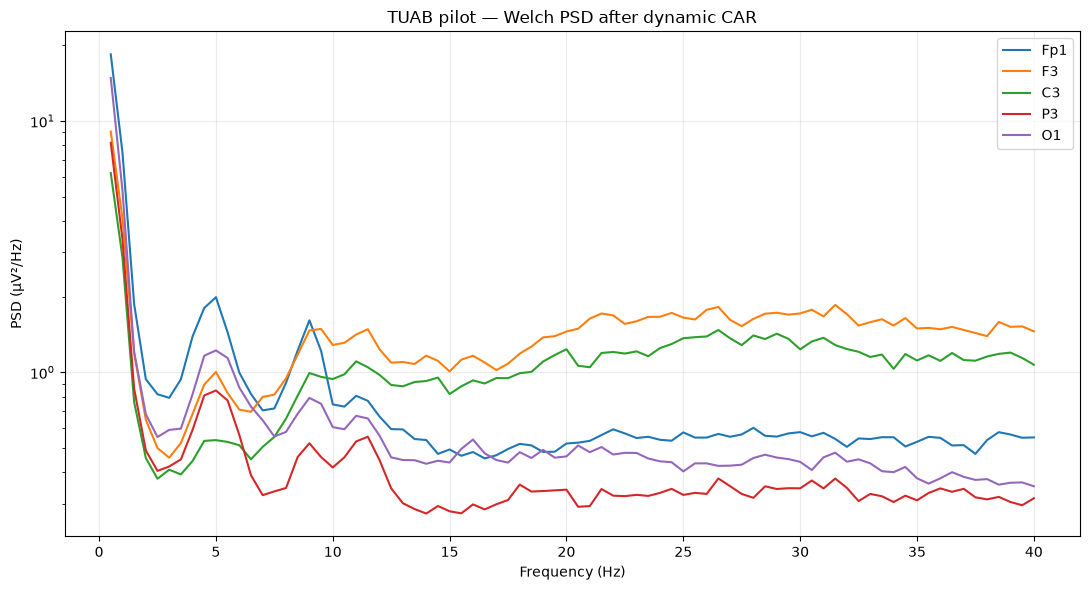


Welch PSD validation: PASSED


In [18]:
def compute_welch_psd(epochs):
    """
    Compute PSD independently for each epoch and channel.

    Input:
        (n_epochs, 19, 1600), microvolts

    Output:
        frequencies: (n_frequencies,)
        psd: (n_epochs, 19, n_frequencies)
             units: µV²/Hz
    """
    freqs, psd = signal.welch(
        epochs,
        fs=SFREQ,
        window="hann",
        nperseg=WELCH_NPERSEG,
        noverlap=WELCH_NOVERLAP,
        detrend="constant",
        scaling="density",
        axis=-1,
    )

    return freqs, psd


freqs, pilot_psd = compute_welch_psd(pilot_car)

assert pilot_psd.shape[:2] == pilot_car.shape[:2]
assert np.isfinite(pilot_psd).all()
assert np.all(pilot_psd >= 0)

print("PSD shape:", pilot_psd.shape)
print("Frequency resolution:", freqs[1] - freqs[0], "Hz")
print("Frequency range:", freqs[0], "to", freqs[-1], "Hz")
print("PSD units: µV²/Hz")

# Plot median PSD across epochs for 5 selected channels
selected_channels = ["Fp1", "F3", "C3", "P3", "O1"]

plt.figure(figsize=(11, 6))

for channel in selected_channels:
    idx = CHANNELS.index(channel)
    median_psd = np.median(pilot_psd[:, idx, :], axis=0)

    mask = (freqs >= 0.5) & (freqs <= 40)

    plt.semilogy(
        freqs[mask],
        median_psd[mask],
        label=channel,
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (µV²/Hz)")
plt.title("TUAB pilot — Welch PSD after dynamic CAR")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\nWelch PSD validation: PASSED")

# Spectral feature extraction

In [19]:
# Cell 8 — Corrected spectral band-power extraction

from scipy.integrate import trapezoid

def integrate_psd_band(freqs, psd, low, high):
    """
    Integrate PSD over [low, high], interpolating
    the PSD at exact band boundaries.

    PSD units: µV²/Hz
    Output units: µV²
    """
    freqs = np.asarray(freqs)

    assert low >= freqs[0]
    assert high <= freqs[-1]
    assert low < high

    inside = (freqs > low) & (freqs < high)

    band_freqs = np.concatenate([
        [low],
        freqs[inside],
        [high],
    ])

    # Interpolate PSD at both boundaries
    left_idx = np.searchsorted(freqs, low, side="right") - 1
    right_idx = np.searchsorted(freqs, high, side="right") - 1

    left_idx = min(max(left_idx, 0), len(freqs) - 2)
    right_idx = min(max(right_idx, 0), len(freqs) - 2)

    def interpolate_at(value, idx):
        f0, f1 = freqs[idx], freqs[idx + 1]
        weight = (value - f0) / (f1 - f0)
        return (
            psd[..., idx] * (1 - weight)
            + psd[..., idx + 1] * weight
        )

    left_power = interpolate_at(low, left_idx)
    right_power = interpolate_at(high, right_idx)

    band_psd = np.concatenate([
        left_power[..., None],
        psd[..., inside],
        right_power[..., None],
    ], axis=-1)

    return trapezoid(
        band_psd,
        x=band_freqs,
        axis=-1,
    )


def extract_band_powers(freqs, psd, bands=BANDS):
    features = {}

    total_power = integrate_psd_band(
        freqs, psd, 0.5, 40.0
    )

    for band_name, (low, high) in bands.items():
        band_power = integrate_psd_band(
            freqs, psd, low, high
        )

        features[f"{band_name}_absolute_power"] = band_power
        features[f"{band_name}_relative_power"] = (
            band_power / np.maximum(total_power, 1e-12)
        )

    return features, total_power


spectral_features, total_power = extract_band_powers(
    freqs, pilot_psd
)

# Validate conservation of integrated power
sum_band_power = sum(
    spectral_features[f"{band}_absolute_power"]
    for band in BANDS
)

relative_error = np.max(
    np.abs(sum_band_power - total_power)
    / np.maximum(total_power, 1e-12)
)

print("Extracted features:", len(spectral_features))
print("Maximum band-power conservation error:", relative_error)

assert relative_error < 1e-5
assert all(
    np.isfinite(values).all()
    for values in spectral_features.values()
)

print("\nCorrected band-power validation: PASSED")

Extracted features: 10
Maximum band-power conservation error: 0.0

Corrected band-power validation: PASSED


# Spectral descriptors and power ratios

In [20]:
def extract_spectral_descriptors(freqs, psd, band_features):
    """
    Input
    -----
    freqs: (n_freqs,)
    psd: (n_epochs, 19, n_freqs), µV²/Hz
    band_features: output dictionary from Cell 8

    Returns
    -------
    dict of arrays, each (n_epochs, 19)
    """

    features = {}

    # Restrict descriptors to 0.5–40 Hz
    mask = (freqs >= 0.5) & (freqs <= 40.0)
    f = freqs[mask]
    p = np.maximum(psd[..., mask], 0.0)

    # Normalized spectral distribution
    power_sum = p.sum(axis=-1, keepdims=True)
    valid = power_sum[..., 0] > 0

    probabilities = np.divide(
        p,
        power_sum,
        out=np.zeros_like(p),
        where=power_sum > 0,
    )

    # Normalized spectral entropy
    entropy = -np.sum(
        np.where(
            probabilities > 0,
            probabilities * np.log(
                np.maximum(probabilities, 1e-12)
            ),
            0.0,
        ),
        axis=-1,
    )

    features["spectral_entropy"] = np.where(
        valid,
        entropy / np.log(len(f)),
        np.nan,
    )

    # Spectral edge frequencies based on cumulative PSD
    # Trapezoidal interval integration
    increments = (
        (p[..., 1:] + p[..., :-1])
        * np.diff(f)
        / 2.0
    )

    cumulative = np.concatenate(
        [
            np.zeros_like(increments[..., :1]),
            np.cumsum(increments, axis=-1),
        ],
        axis=-1,
    )

    total = cumulative[..., -1]

    for fraction, name in [
        (0.90, "spectral_edge_90"),
        (0.95, "spectral_edge_95"),
    ]:
        target = fraction * total
        idx = np.sum(
            cumulative < target[..., None],
            axis=-1,
        )
        idx = np.clip(idx, 1, len(f) - 1)

        left_idx = idx - 1

        c0 = np.take_along_axis(
            cumulative, left_idx[..., None], axis=-1
        )[..., 0]

        c1 = np.take_along_axis(
            cumulative, idx[..., None], axis=-1
        )[..., 0]

        f0 = f[left_idx]
        f1 = f[idx]

        fraction_in_bin = np.divide(
            target - c0,
            c1 - c0,
            out=np.zeros_like(target),
            where=(c1 > c0),
        )

        edge = f0 + fraction_in_bin * (f1 - f0)

        features[name] = np.where(
            total > 0, edge, np.nan
        )

    # Power ratios: calculated from linear absolute powers
    delta = band_features["delta_absolute_power"]
    theta = band_features["theta_absolute_power"]
    alpha = band_features["alpha_absolute_power"]
    beta = band_features["beta_absolute_power"]

    def safe_ratio(numerator, denominator):
        # Zero denominators become missing rather than
        # producing misleading extreme values.
        return np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan),
            where=denominator > 1e-12,
        )

    features["delta_alpha_ratio"] = safe_ratio(delta, alpha)
    features["theta_alpha_ratio"] = safe_ratio(theta, alpha)
    features["theta_beta_ratio"] = safe_ratio(theta, beta)
    features["slow_fast_ratio"] = safe_ratio(
        delta + theta,
        alpha + beta,
    )

    return features


spectral_descriptors = extract_spectral_descriptors(
    freqs,
    pilot_psd,
    spectral_features,
)

print("Extracted descriptors:", len(spectral_descriptors))

for name, values in spectral_descriptors.items():
    print(
        f"{name:25s}",
        f"shape={values.shape}",
        f"missing={np.isnan(values).sum()}",
        f"median={np.nanmedian(values):.4f}",
    )

assert len(spectral_descriptors) == 7
assert all(
    values.shape == (155, 19)
    for values in spectral_descriptors.values()
)

assert all(
    not np.isinf(values).any()
    for values in spectral_descriptors.values()
)

for name in ["spectral_edge_90", "spectral_edge_95"]:
    values = spectral_descriptors[name]
    valid_values = values[np.isfinite(values)]
    assert np.all(
        (valid_values >= 0.5) & (valid_values <= 40)
    )

entropy_values = spectral_descriptors["spectral_entropy"]
valid_entropy = entropy_values[np.isfinite(entropy_values)]

assert np.all(
    (valid_entropy >= -1e-10)
    & (valid_entropy <= 1 + 1e-10)
)

print("\nSpectral descriptor validation: PASSED")

Extracted descriptors: 7
spectral_entropy          shape=(155, 19) missing=0 median=0.9326
spectral_edge_90          shape=(155, 19) missing=0 median=35.6529
spectral_edge_95          shape=(155, 19) missing=0 median=37.7453
delta_alpha_ratio         shape=(155, 19) missing=0 median=1.3168
theta_alpha_ratio         shape=(155, 19) missing=0 median=0.6380
theta_beta_ratio          shape=(155, 19) missing=0 median=0.1830
slow_fast_ratio           shape=(155, 19) missing=0 median=0.4615

Spectral descriptor validation: PASSED


# Temporal and Hjorth features

In [21]:
def extract_temporal_features(epochs):
    """
    Input: (n_epochs, 19, 1600), microvolts
    Output: dict of (n_epochs, 19) feature arrays
    """
    x = np.asarray(epochs, dtype=np.float64)

    features = {}

    features["rms"] = np.sqrt(np.mean(x**2, axis=-1))

    q75 = np.percentile(x, 75, axis=-1)
    q25 = np.percentile(x, 25, axis=-1)
    features["iqr"] = q75 - q25

    median = np.median(x, axis=-1, keepdims=True)
    features["mad"] = np.median(
        np.abs(x - median), axis=-1
    )

    features["line_length"] = np.mean(
        np.abs(np.diff(x, axis=-1)), axis=-1
    )

    features["peak_to_peak"] = np.ptp(x, axis=-1)

    # Hjorth parameters
    dx = np.diff(x, axis=-1)
    ddx = np.diff(dx, axis=-1)

    var_x = np.var(x, axis=-1)
    var_dx = np.var(dx, axis=-1)
    var_ddx = np.var(ddx, axis=-1)

    eps = 1e-12

    mobility = np.sqrt(
        var_dx / np.maximum(var_x, eps)
    )

    derivative_mobility = np.sqrt(
        var_ddx / np.maximum(var_dx, eps)
    )

    complexity = (
        derivative_mobility / np.maximum(mobility, eps)
    )

    # Undefined features remain missing
    mobility[var_x <= eps] = np.nan
    complexity[(var_x <= eps) | (var_dx <= eps)] = np.nan

    features["hjorth_mobility"] = mobility
    features["hjorth_complexity"] = complexity

    return features


temporal_features = extract_temporal_features(pilot_car)

print("Extracted temporal features:", len(temporal_features))

for name, values in temporal_features.items():
    print(
        f"{name:22s}",
        f"shape={values.shape}",
        f"missing={np.isnan(values).sum()}",
        f"median={np.nanmedian(values):.6f}"
    )

assert len(temporal_features) == 7

for values in temporal_features.values():
    assert values.shape == (155, 19)
    assert not np.isinf(values).any()

print("\nTemporal feature validation: PASSED")

Extracted temporal features: 7
rms                    shape=(155, 19) missing=0 median=7.937594
iqr                    shape=(155, 19) missing=0 median=10.489369
mad                    shape=(155, 19) missing=0 median=5.246863
line_length            shape=(155, 19) missing=0 median=3.991083
peak_to_peak           shape=(155, 19) missing=0 median=54.975504
hjorth_mobility        shape=(155, 19) missing=0 median=0.695262
hjorth_complexity      shape=(155, 19) missing=0 median=1.441537

Temporal feature validation: PASSED


# Recording-level aggregation

In [22]:
def aggregate_recording_features(
    spectral_features,
    spectral_descriptors,
    temporal_features,
    channels=CHANNELS,
):
    """
    Aggregate epoch-level features into one recording-level vector.

    Each input feature has shape:
        (n_epochs, 19)

    Returns
    -------
    dict
        One scalar per channel-feature-aggregation combination.
    """

    all_features = {
        **spectral_features,
        **spectral_descriptors,
        **temporal_features,
    }

    assert len(all_features) == 24

    recording_features = {}

    for feature_name, values in all_features.items():
        values = np.asarray(values, dtype=np.float64)

        assert values.ndim == 2
        assert values.shape[1] == len(channels)

        with np.errstate(all="ignore"):
            medians = np.nanmedian(values, axis=0)

            q75 = np.nanpercentile(values, 75, axis=0)
            q25 = np.nanpercentile(values, 25, axis=0)

            iqrs = q75 - q25

        for channel_idx, channel in enumerate(channels):
            recording_features[
                f"car__{channel}__{feature_name}__median"
            ] = float(medians[channel_idx])

            recording_features[
                f"car__{channel}__{feature_name}__iqr"
            ] = float(iqrs[channel_idx])

    return recording_features


pilot_recording_features = aggregate_recording_features(
    spectral_features,
    spectral_descriptors,
    temporal_features,
)

print("Features per channel:", 24)
print("Channels:", len(CHANNELS))
print("Aggregation statistics:", 2)
print("Recording-level features:", len(pilot_recording_features))

assert len(pilot_recording_features) == 24 * 19 * 2

feature_values = np.array(
    list(pilot_recording_features.values()),
    dtype=np.float64,
)

print("Missing values:", np.isnan(feature_values).sum())
print("Infinite values:", np.isinf(feature_values).sum())

assert not np.isinf(feature_values).any()

print("\nRecording-level aggregation: PASSED")

Features per channel: 24
Channels: 19
Aggregation statistics: 2
Recording-level features: 912
Missing values: 0
Infinite values: 0

Recording-level aggregation: PASSED


# EEG regional feature aggregation

In [23]:
def aggregate_regional_features(
    spectral_features,
    spectral_descriptors,
    temporal_features,
    channels=CHANNELS,
    regions=REGIONS,
):
    """
    Regional aggregation:
      1. Median across channels within each region, per epoch
      2. Median and IQR across epochs

    Returns one dictionary of regional recording-level features.
    """

    all_features = {
        **spectral_features,
        **spectral_descriptors,
        **temporal_features,
    }

    assert len(all_features) == 24

    channel_to_idx = {
        channel: idx
        for idx, channel in enumerate(channels)
    }

    # Verify anatomical region definitions
    regional_channels = [
        channel
        for region_channels in regions.values()
        for channel in region_channels
    ]

    assert len(regions) == 5
    assert len(regional_channels) == len(channels)
    assert set(regional_channels) == set(channels)
    assert len(regional_channels) == len(set(regional_channels))

    regional_features = {}

    for feature_name, values in all_features.items():
        values = np.asarray(values, dtype=np.float64)

        assert values.ndim == 2
        assert values.shape[1] == len(channels)

        for region_name, region_channels in regions.items():
            indices = [
                channel_to_idx[channel]
                for channel in region_channels
            ]

            # One regional value per epoch
            region_epoch_values = np.nanmedian(
                values[:, indices],
                axis=1,
            )

            # Recording-level temporal aggregation
            median_value = np.nanmedian(region_epoch_values)

            q75, q25 = np.nanpercentile(
                region_epoch_values,
                [75, 25],
            )

            regional_features[
                f"car__region_{region_name}__{feature_name}__median"
            ] = float(median_value)

            regional_features[
                f"car__region_{region_name}__{feature_name}__iqr"
            ] = float(q75 - q25)

    return regional_features


pilot_regional_features = aggregate_regional_features(
    spectral_features,
    spectral_descriptors,
    temporal_features,
)

# Combine channel-level and regional features
pilot_full_features = {
    **pilot_recording_features,
    **pilot_regional_features,
}

print("Channel-level features:", len(pilot_recording_features))
print("Regional features:", len(pilot_regional_features))
print("Total recording features:", len(pilot_full_features))

values = np.asarray(
    list(pilot_full_features.values()),
    dtype=np.float64,
)

print("Missing values:", np.isnan(values).sum())
print("Infinite values:", np.isinf(values).sum())

assert len(pilot_regional_features) == 240
assert len(pilot_full_features) == 1152
assert np.isfinite(values).all()

print("\nRegional feature aggregation: PASSED")

Channel-level features: 912
Regional features: 240
Total recording features: 1152
Missing values: 0
Infinite values: 0

Regional feature aggregation: PASSED


# Six-recording pilot validation

In [24]:
def extract_recording_features(npz_path):
    with np.load(npz_path, allow_pickle=False) as data:
        epochs = data["original_reference"]
        sfreq = float(data["sfreq"])
        channels = list(data["channels"])

    assert sfreq == SFREQ
    assert channels == CHANNELS
    assert epochs.ndim == 3
    assert epochs.shape[1:] == (19, 1600)
    assert np.isfinite(epochs).all()

    # Apply dynamic common average reference
    epochs_car = apply_car(epochs)

    # Spectral extraction
    recording_freqs, recording_psd = compute_welch_psd(
        epochs_car
    )

    band_features, _ = extract_band_powers(
        recording_freqs,
        recording_psd,
    )

    spectral_descriptors = extract_spectral_descriptors(
        recording_freqs,
        recording_psd,
        band_features,
    )

    # Temporal extraction
    temporal_features = extract_temporal_features(
        epochs_car
    )

    # Channel-level aggregation
    channel_features = aggregate_recording_features(
        band_features,
        spectral_descriptors,
        temporal_features,
    )

    # Regional aggregation
    regional_features = aggregate_regional_features(
        band_features,
        spectral_descriptors,
        temporal_features,
    )

    return {
        **channel_features,
        **regional_features,
    }


pilot_results = []

for _, record in pilot_df.iterrows():
    npz_path = resolve_npz_path(record["output_file"])

    features = extract_recording_features(npz_path)

    pilot_results.append({
        "filepath": record["filepath"],
        "patient_id": record["patient_id"],
        "label": record["label"],
        "split": record["split"],
        **features,
    })

pilot_features_df = pd.DataFrame(pilot_results)

feature_columns = [
    column
    for column in pilot_features_df.columns
    if column.startswith("car__")
]

print("Pilot recordings:", len(pilot_features_df))
print("Feature columns:", len(feature_columns))
print("Labels:", pilot_features_df["label"].value_counts().to_dict())

feature_matrix = pilot_features_df[feature_columns].to_numpy(
    dtype=np.float64
)

print("Missing values:", np.isnan(feature_matrix).sum())
print("Infinite values:", np.isinf(feature_matrix).sum())

assert len(pilot_features_df) == 6
assert len(feature_columns) == 1152
assert np.isfinite(feature_matrix).all()
assert not pilot_features_df[feature_columns].columns.duplicated().any()

print("\nSix-recording pilot validation: PASSED")

Pilot recordings: 6
Feature columns: 1152
Labels: {'abnormal': 3, 'normal': 3}
Missing values: 0
Infinite values: 0

Six-recording pilot validation: PASSED


# Runtime and memory benchmark

In [25]:
import time
import gc
import tracemalloc

benchmark_results = []

for _, record in pilot_df.iterrows():
    npz_path = resolve_npz_path(record["output_file"])

    gc.collect()
    tracemalloc.start()

    start = time.perf_counter()

    features = extract_recording_features(npz_path)

    elapsed = time.perf_counter() - start

    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    benchmark_results.append({
        "recording_id": npz_path.stem,
        "label": record["label"],
        "seconds": elapsed,
        "peak_python_memory_mb": peak_memory / (1024 ** 2),
        "features": len(features),
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

mean_seconds = benchmark_df["seconds"].mean()
estimated_hours = mean_seconds * len(metadata_df) / 3600

print(f"\nMean time per recording: {mean_seconds:.2f} seconds")
print(f"Estimated full-dataset runtime: {estimated_hours:.2f} hours")
print(
    "Maximum traced Python memory:",
    f"{benchmark_df['peak_python_memory_mb'].max():.2f} MB"
)

assert (benchmark_df["features"] == 1152).all()

print("\nRuntime benchmark: PASSED")

,recording_id,label,seconds,peak_python_memory_mb,features
0,ba9e5e3c60c74532,abnormal,0.936875,184.889155,1152
1,4506a81a3b502ba9,abnormal,1.598871,327.963118,1152
2,3c4926e8e48a2348,abnormal,0.858504,187.273561,1152
3,3d588b0cd231487d,normal,1.394851,292.194609,1152
4,1601ea80851b167c,normal,0.815583,188.466619,1152
5,d8341ce6ca8831b2,normal,0.830003,188.465801,1152



Mean time per recording: 1.07 seconds
Estimated full-dataset runtime: 0.89 hours
Maximum traced Python memory: 327.96 MB

Runtime benchmark: PASSED


# Prepare full-dataset extraction

In [26]:
FEATURE_ROOT = PROJECT_ROOT / "tuab_feature_extraction"
FEATURE_DIR = FEATURE_ROOT / "features"
CHECKPOINT_DIR = FEATURE_ROOT / "checkpoints"
LOG_DIR = FEATURE_ROOT / "logs"

for directory in [
    FEATURE_DIR,
    CHECKPOINT_DIR,
    LOG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# Freeze feature-column order from validated pilot
FEATURE_COLUMNS = sorted(
    column
    for column in pilot_features_df.columns
    if column.startswith("car__")
)

assert len(FEATURE_COLUMNS) == 1152
assert len(set(FEATURE_COLUMNS)) == 1152

# Validate extraction manifest
extraction_df = metadata_df.copy()

assert len(extraction_df) == 2993
assert extraction_df["filepath"].is_unique
assert extraction_df["output_file"].notna().all()
assert extraction_df["patient_id"].notna().all()
assert extraction_df["label"].isin(["normal", "abnormal"]).all()
assert extraction_df["split"].isin(
    ["train", "val", "eval"]
).all()

# Verify all source NPZ files exist
missing_files = []

for output_file in extraction_df["output_file"]:
    try:
        path = resolve_npz_path(output_file)
        if not path.is_file():
            missing_files.append(str(output_file))
    except (FileNotFoundError, ValueError):
        missing_files.append(str(output_file))

print("Recordings:", len(extraction_df))
print("Feature columns:", len(FEATURE_COLUMNS))
print("Missing NPZ files:", len(missing_files))
print("Split counts:")
print(extraction_df["split"].value_counts().sort_index())

assert len(missing_files) == 0

# Save the frozen schema
schema_path = FEATURE_ROOT / "metadata" / "feature_schema.json"
schema_path.parent.mkdir(parents=True, exist_ok=True)

schema = {
    "version": "1.0",
    "reference": "dynamic_19_channel_CAR",
    "sampling_frequency_hz": SFREQ,
    "epoch_seconds": EPOCH_SECONDS,
    "feature_count": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "channels": CHANNELS,
    "regions": REGIONS,
    "frequency_bands_hz": BANDS,
    "welch_nperseg": WELCH_NPERSEG,
    "welch_noverlap": WELCH_NOVERLAP,
    "aggregation": {
        "channel": ["median", "iqr"],
        "region": [
            "median_across_channels_per_epoch",
            "median_across_epochs",
            "iqr_across_epochs",
        ],
    },
}

with open(schema_path, "w", encoding="utf-8") as file:
    json.dump(schema, file, indent=2)

print("\nFeature schema:", schema_path)
print("Full extraction preparation: PASSED")

Recordings: 2993
Feature columns: 1152
Missing NPZ files: 0
Split counts:
split
eval      276
train    2173
val       544
Name: count, dtype: int64

Feature schema: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/metadata/feature_schema.json
Full extraction preparation: PASSED


# Resumable full-dataset feature extraction

In [27]:
import os
import time
import gc
from tqdm.auto import tqdm

BATCH_SIZE = 50

CHECKPOINT_PATH = CHECKPOINT_DIR / "extraction_progress.csv"
ERROR_LOG_PATH = LOG_DIR / "extraction_errors.csv"

METADATA_COLUMNS = [
    "filepath",
    "patient_id",
    "label",
    "split",
]

OUTPUT_COLUMNS = METADATA_COLUMNS + FEATURE_COLUMNS

# Resume previously completed recordings
if CHECKPOINT_PATH.exists():
    completed_df = pd.read_csv(CHECKPOINT_PATH)

    assert completed_df["filepath"].is_unique
    assert set(completed_df.columns) == set(OUTPUT_COLUMNS)

    completed_df = completed_df[OUTPUT_COLUMNS]

    print(f"Resuming: {len(completed_df)} recordings completed")

else:
    completed_df = pd.DataFrame(columns=OUTPUT_COLUMNS)
    print("Starting new extraction")

completed_ids = set(completed_df["filepath"])

# Load previous errors, if any
if ERROR_LOG_PATH.exists():
    errors_df = pd.read_csv(ERROR_LOG_PATH)
    previous_errors = errors_df.to_dict("records")
else:
    previous_errors = []

pending_df = extraction_df[
    ~extraction_df["filepath"].isin(completed_ids)
].copy()

print("Remaining recordings:", len(pending_df))

batch_results = []
new_errors = []
start_time = time.perf_counter()


def save_progress(batch_results):
    """Atomically save completed feature rows."""

    global completed_df

    if not batch_results:
        return

    batch_df = pd.DataFrame(batch_results)

    assert set(batch_df.columns) == set(OUTPUT_COLUMNS)

    batch_df = batch_df[OUTPUT_COLUMNS]

    completed_df = pd.concat(
        [completed_df, batch_df],
        ignore_index=True,
    )

    assert completed_df["filepath"].is_unique

    temporary_path = CHECKPOINT_PATH.with_suffix(".tmp")

    completed_df.to_csv(temporary_path, index=False)

    os.replace(temporary_path, CHECKPOINT_PATH)


for _, record in tqdm(
    pending_df.iterrows(),
    total=len(pending_df),
    desc="TUAB feature extraction",
):

    try:
        npz_path = resolve_npz_path(record["output_file"])

        features = extract_recording_features(npz_path)

        assert len(features) == 1152
        assert set(features) == set(FEATURE_COLUMNS)

        feature_values = np.asarray(
            list(features.values()),
            dtype=np.float64,
        )

        assert not np.isinf(feature_values).any()

        result = {
            column: record[column]
            for column in METADATA_COLUMNS
        }

        result.update(features)

        batch_results.append(result)

    except Exception as error:
        new_errors.append({
            "filepath": record["filepath"],
            "output_file": record["output_file"],
            "error_type": type(error).__name__,
            "error_message": str(error),
        })

    if len(batch_results) >= BATCH_SIZE:
        save_progress(batch_results)
        batch_results = []
        gc.collect()


# Save final incomplete batch
save_progress(batch_results)

# Save error log
all_errors = previous_errors + new_errors

if all_errors:
    pd.DataFrame(all_errors).to_csv(
        ERROR_LOG_PATH,
        index=False,
    )

elapsed = time.perf_counter() - start_time

print("\nExtraction run finished")
print("Completed recordings:", len(completed_df))
print("New errors:", len(new_errors))
print("Elapsed minutes:", round(elapsed / 60, 2))
print("Checkpoint:", CHECKPOINT_PATH)

if len(completed_df) == len(extraction_df):
    print("\nFull TUAB feature extraction: PASSED")
else:
    print("\nExtraction incomplete — inspect errors or resume")

Starting new extraction
Remaining recordings: 2993


TUAB feature extraction:   0%|          | 0/2993 [00:00<?, ?it/s]

/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: RuntimeWarning: All-NaN slice encountered
  region_epoch_values = np.nanmedian(
/tmp/ipykernel_314614/3243240775.py:56: 


Extraction run finished
Completed recordings: 2993
New errors: 0
Elapsed minutes: 41.57
Checkpoint: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/checkpoints/extraction_progress.csv

Full TUAB feature extraction: PASSED


# Full feature dataset quality audit

In [28]:
features_df = pd.read_csv(CHECKPOINT_PATH)

feature_columns = FEATURE_COLUMNS
X = features_df[feature_columns]

# 1. Dataset integrity
print("Dataset shape:", features_df.shape)
print("Unique recordings:", features_df["filepath"].nunique())
print("Duplicate recordings:", features_df["filepath"].duplicated().sum())

# 2. Missing and infinite values
missing = X.isna().sum()
infinite_count = np.isinf(X.to_numpy(dtype=np.float64)).sum()

print("\nTotal missing values:", int(missing.sum()))
print("Features containing NaN:", int((missing > 0).sum()))
print("Infinite values:", int(infinite_count))

# 3. Most affected features
print("\nTop 15 features by missing values:")
print(missing.sort_values(ascending=False).head(15))

# 4. Recordings affected by missing values
rows_with_nan = X.isna().any(axis=1)

print("\nRecordings with NaN:", int(rows_with_nan.sum()))

print("\nMissingness by diagnostic label:")
print(
    features_df.assign(has_nan=rows_with_nan)
    .groupby("label")["has_nan"]
    .agg(["sum", "count", "mean"])
)

print("\nMissingness by split:")
print(
    features_df.assign(has_nan=rows_with_nan)
    .groupby("split")["has_nan"]
    .agg(["sum", "count", "mean"])
)

# 5. Constant and entirely missing features
all_nan = X.isna().all()
constant = X.nunique(dropna=True) <= 1

print("\nEntirely NaN features:", int(all_nan.sum()))
print("Constant/near-empty features:", int(constant.sum()))

# 6. Structural validation
assert features_df.shape == (2993, 1156)
assert features_df["filepath"].is_unique
assert infinite_count == 0

print("\nStructural integrity: PASSED")

Dataset shape: (2993, 1156)
Unique recordings: 2993
Duplicate recordings: 0

Total missing values: 0
Features containing NaN: 0
Infinite values: 0

Top 15 features by missing values:
car__C3__alpha_absolute_power__iqr       0
car__C3__alpha_absolute_power__median    0
car__C3__alpha_relative_power__iqr       0
car__C3__alpha_relative_power__median    0
car__C3__beta_absolute_power__iqr        0
car__C3__beta_absolute_power__median     0
car__C3__beta_relative_power__iqr        0
car__C3__beta_relative_power__median     0
car__C3__delta_absolute_power__iqr       0
car__C3__delta_absolute_power__median    0
car__C3__delta_alpha_ratio__iqr          0
car__C3__delta_alpha_ratio__median       0
car__C3__delta_relative_power__iqr       0
car__C3__delta_relative_power__median    0
car__C3__hjorth_complexity__iqr          0
dtype: int64

Recordings with NaN: 0

Missingness by diagnostic label:
          sum  count  mean
label                     
abnormal    0   1472   0.0
normal      0   1521

/tmp/ipykernel_314614/2454232186.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features_df.assign(has_nan=rows_with_nan)
/tmp/ipykernel_314614/2454232186.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features_df.assign(has_nan=rows_with_nan)


# Export final feature dataset

In [29]:
import time

FINAL_FEATURE_PATH = (
    FEATURE_DIR / "tuab_recording_features.parquet"
)

# Preserve fixed metadata and feature order
final_df = features_df[
    METADATA_COLUMNS + FEATURE_COLUMNS
].copy()

# Final validation
assert final_df.shape == (2993, 1156)
assert final_df["filepath"].is_unique
assert not final_df[FEATURE_COLUMNS].isna().any().any()
assert np.isfinite(
    final_df[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
).all()

# Export compressed Parquet
start = time.perf_counter()

final_df.to_parquet(
    FINAL_FEATURE_PATH,
    engine="pyarrow",
    compression="zstd",
    index=False,
)

# Read back and verify
verified_df = pd.read_parquet(FINAL_FEATURE_PATH)

assert verified_df.shape == final_df.shape
assert verified_df.columns.tolist() == final_df.columns.tolist()
pd.testing.assert_frame_equal(
    verified_df,
    final_df,
    check_exact=True,
)

size_mb = FINAL_FEATURE_PATH.stat().st_size / (1024 ** 2)

print("Final dataset:", FINAL_FEATURE_PATH)
print("Shape:", verified_df.shape)
print("Size:", f"{size_mb:.2f} MB")
print("Export time:", f"{time.perf_counter() - start:.2f} s")
print("\nFinal feature dataset export: PASSED")

Final dataset: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/features/tuab_recording_features.parquet
Shape: (2993, 1156)
Size: 28.68 MB
Export time: 0.57 s

Final feature dataset export: PASSED


# Feature distribution and outlier audit

In [30]:
X = verified_df[FEATURE_COLUMNS]

# Audit only the training split
train_mask = verified_df["split"] == "train"
X_train = X.loc[train_mask]

# Summarize selected features across recordings
selected_features = [
    "car__F3__alpha_absolute_power__median",
    "car__F3__theta_beta_ratio__median",
    "car__F3__rms__median",
    "car__F3__hjorth_complexity__median",
    "car__region_frontal__theta_absolute_power__median",
]

summary = X_train[selected_features].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

display(summary)

# Robust outlier audit using the 3 × IQR rule
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower = q1 - 3 * iqr
upper = q3 + 3 * iqr

outlier_mask = X_train.lt(lower) | X_train.gt(upper)

outlier_counts = outlier_mask.sum().sort_values(
    ascending=False
)

print("Training recordings:", len(X_train))
print("Features audited:", len(FEATURE_COLUMNS))
print(
    "Features with at least one flagged outlier:",
    int((outlier_counts > 0).sum())
)
print(
    "Recordings with at least one flagged feature:",
    int(outlier_mask.any(axis=1).sum())
)

print("\nTop 15 features by outlier count:")
display(outlier_counts.head(15))

assert len(X_train) == 2173
assert len(FEATURE_COLUMNS) == 1152

print("\nFeature distribution audit: PASSED")

,count,mean,std,min,1%,25%,50%,75%,99%,max
car__F3__alpha_absolute_power__median,2173.0,71.826736,2928.313502,0.003054,0.274426,2.549494,5.185762,10.203930,48.394883,136508.485840
car__F3__theta_beta_ratio__median,2173.0,2.096177,4.100968,0.029942,0.093522,0.495070,0.983425,2.152404,19.034742,108.967238
car__F3__rms__median,2173.0,9.381213,41.587666,0.239836,2.992033,5.435165,6.924204,9.466971,29.778680,1916.557390
car__F3__hjorth_complexity__median,2173.0,2.766029,1.387427,1.087607,1.359046,1.942970,2.371777,3.106567,7.874270,22.637979
car__region_frontal__theta_absolute_power__median,2173.0,175.437663,7614.949082,0.005553,0.771277,3.186135,5.404853,11.292986,107.117881,354978.118164


Training recordings: 2173
Features audited: 1152
Features with at least one flagged outlier: 1043
Recordings with at least one flagged feature: 1601

Top 15 features by outlier count:


car__C4__low_gamma_absolute_power__iqr                210
car__T5__low_gamma_absolute_power__iqr                205
car__F8__low_gamma_absolute_power__iqr                199
car__region_central__low_gamma_absolute_power__iqr    198
car__C3__low_gamma_absolute_power__iqr                198
car__F7__low_gamma_absolute_power__iqr                190
car__P4__low_gamma_absolute_power__iqr                186
car__Fp1__low_gamma_absolute_power__iqr               185
car__F3__low_gamma_absolute_power__iqr                185
car__T6__low_gamma_absolute_power__iqr                184
car__T3__delta_absolute_power__median                 184
car__Fp2__low_gamma_absolute_power__iqr               183
car__T3__low_gamma_absolute_power__iqr                182
car__T4__low_gamma_absolute_power__iqr                180
car__F4__low_gamma_absolute_power__iqr                178
dtype: int64


Feature distribution audit: PASSED


# Quantify feature skewness

In [31]:
train_features = verified_df.loc[
    verified_df["split"] == "train",
    FEATURE_COLUMNS
]

skewness = train_features.skew()

skew_summary = pd.DataFrame({
    "feature": skewness.index,
    "skewness": skewness.values,
})

skew_summary["absolute_skewness"] = (
    skew_summary["skewness"].abs()
)

skew_summary = skew_summary.sort_values(
    "absolute_skewness",
    ascending=False,
)

print("Total features:", len(skew_summary))

print(
    "Features with |skewness| > 1:",
    int((skew_summary["absolute_skewness"] > 1).sum())
)

print(
    "Features with |skewness| > 3:",
    int((skew_summary["absolute_skewness"] > 3).sum())
)

print("\nTop 15 most skewed features:")
display(skew_summary.head(15))

# Summarize by feature family
for family in [
    "absolute_power",
    "relative_power",
    "spectral_entropy",
    "spectral_edge",
    "ratio",
    "rms",
    "hjorth",
]:
    family_values = skew_summary.loc[
        skew_summary["feature"].str.contains(
            family, regex=False
        ),
        "absolute_skewness",
    ]

    if len(family_values):
        print(
            f"{family:20s}",
            f"n={len(family_values):4d}",
            f"median |skew|={family_values.median():.3f}"
        )

assert len(skew_summary) == 1152
assert np.isfinite(skew_summary["skewness"]).all()

print("\nSkewness audit: PASSED")

Total features: 1152
Features with |skewness| > 1: 1004
Features with |skewness| > 3: 716

Top 15 most skewed features:


,feature,skewness,absolute_skewness
311,car__F8__low_gamma_absolute_power__median,46.615412,46.615412
616,car__P3__theta_absolute_power__iqr,46.615349,46.615349
568,car__O2__theta_absolute_power__iqr,46.615335,46.615335
1048,car__region_occipital__theta_absolute_power__iqr,46.615334,46.615334
1144,car__region_temporal__theta_absolute_power__iqr,46.615333,46.615333
520,car__O1__theta_absolute_power__iqr,46.615332,46.615332
760,car__T3__theta_absolute_power__iqr,46.615329,46.615329
472,car__Fz__theta_absolute_power__iqr,46.615305,46.615305
440,car__Fz__delta_absolute_power__iqr,46.615296,46.615296
1000,car__region_frontal__theta_absolute_power__iqr,46.615286,46.615286


absolute_power       n= 240 median |skew|=46.590
relative_power       n= 240 median |skew|=1.380
spectral_entropy     n=  48 median |skew|=1.052
spectral_edge        n=  96 median |skew|=0.856
ratio                n= 192 median |skew|=6.538
rms                  n=  48 median |skew|=44.615
hjorth               n=  96 median |skew|=2.462

Skewness audit: PASSED


# Identify recordings responsible for extreme skewness

In [32]:
investigation_features = [
    "car__F8__low_gamma_absolute_power__median",
    "car__P3__theta_absolute_power__iqr",
    "car__F3__rms__median",
]

train_df = verified_df.loc[
    verified_df["split"] == "train"
].copy()

for feature in investigation_features:

    print(f"\n{'=' * 70}")
    print("Feature:", feature)

    values = train_df[feature]

    print("Median:", values.median())
    print("99th percentile:", values.quantile(0.99))
    print("Maximum:", values.max())

    print("\nTop 5 recordings:")

    top_records = train_df.nlargest(5, feature)[
        ["filepath", "patient_id", "label", feature]
    ]

    display(top_records)

    print(
        "Maximum / 99th percentile:",
        values.max() / max(values.quantile(0.99), 1e-12)
    )

# Check whether a few recordings dominate many features
X_train = train_df[FEATURE_COLUMNS]

max_record_indices = X_train.idxmax(axis=0)

dominant_recordings = (
    max_record_indices.value_counts()
    .head(10)
)

print("\nRecordings holding the maximum across most features:")

display(
    train_df.loc[
        dominant_recordings.index,
        ["filepath", "patient_id", "label"]
    ].assign(
        feature_maximum_count=dominant_recordings.values
    )
)

print("\nExtreme-value investigation: COMPLETED")


Feature: car__F8__low_gamma_absolute_power__median
Median: 0.8295369111001492
99th percentile: 53.89786825656949
Maximum: 9857132.654296877

Top 5 recordings:


,filepath,patient_id,label,car__F8__low_gamma_absolute_power__median
1827,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_...,aaaaanvd,normal,9.857133e+06
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,5.413960e+03
718,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanbp_s00...,aaaaanbp,abnormal,4.477785e+03
245,TUAB/edf/train/abnormal/01_tcp_ar/aaaaajnr_s00...,aaaaajnr,abnormal,7.794479e+02
801,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanrb_s00...,aaaaanrb,abnormal,5.493067e+02


Maximum / 99th percentile: 182885.38996336676

Feature: car__P3__theta_absolute_power__iqr
Median: 2.5834814105182886
99th percentile: 62.72470441496007
Maximum: 1445923.3515625

Top 5 recordings:


,filepath,patient_id,label,car__P3__theta_absolute_power__iqr
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,1.445923e+06
1827,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_...,aaaaanvd,normal,1.294043e+03
62,TUAB/edf/train/abnormal/01_tcp_ar/aaaaacrz_s00...,aaaaacrz,abnormal,9.455897e+02
745,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanjn_s00...,aaaaanjn,abnormal,3.010613e+02
718,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanbp_s00...,aaaaanbp,abnormal,2.731080e+02


Maximum / 99th percentile: 23051.89582077396

Feature: car__F3__rms__median
Median: 6.924203898479335
99th percentile: 29.77867993484112
Maximum: 1916.5573903001268

Top 5 recordings:


,filepath,patient_id,label,car__F3__rms__median
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,1916.557390
1827,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_...,aaaaanvd,normal,213.544650
751,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanky_s00...,aaaaanky,abnormal,140.342207
718,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanbp_s00...,aaaaanbp,abnormal,56.068457
182,TUAB/edf/train/abnormal/01_tcp_ar/aaaaaict_s00...,aaaaaict,abnormal,52.001423


Maximum / 99th percentile: 64.36005204037774

Recordings holding the maximum across most features:


,filepath,patient_id,label,feature_maximum_count
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,429
1827,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_...,aaaaanvd,normal,114
686,TUAB/edf/train/abnormal/01_tcp_ar/aaaaamuu_s00...,aaaaamuu,abnormal,71
201,TUAB/edf/train/abnormal/01_tcp_ar/aaaaaivl_s00...,aaaaaivl,abnormal,64
132,TUAB/edf/train/abnormal/01_tcp_ar/aaaaagbi_s00...,aaaaagbi,abnormal,35
974,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaa_s00...,aaaaapaa,abnormal,34
636,TUAB/edf/train/abnormal/01_tcp_ar/aaaaampk_s00...,aaaaampk,abnormal,28
1051,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapsb_s00...,aaaaapsb,abnormal,25
1029,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapmr_s00...,aaaaapmr,abnormal,24
635,TUAB/edf/train/abnormal/01_tcp_ar/aaaaampf_s00...,aaaaampf,abnormal,18



Extreme-value investigation: COMPLETED


# Investigate the two recordings


Patient: aaaaapaw
Label: abnormal
Recording: TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s002_t004.edf
Epochs: 135
Median epoch RMS (µV): 1754.0498693639722
Maximum epoch RMS (µV): 4611.669333120622
Maximum absolute amplitude (µV): 14862.866
Epochs with peak > 500 µV: 135
Epochs with peak > 1000 µV: 135


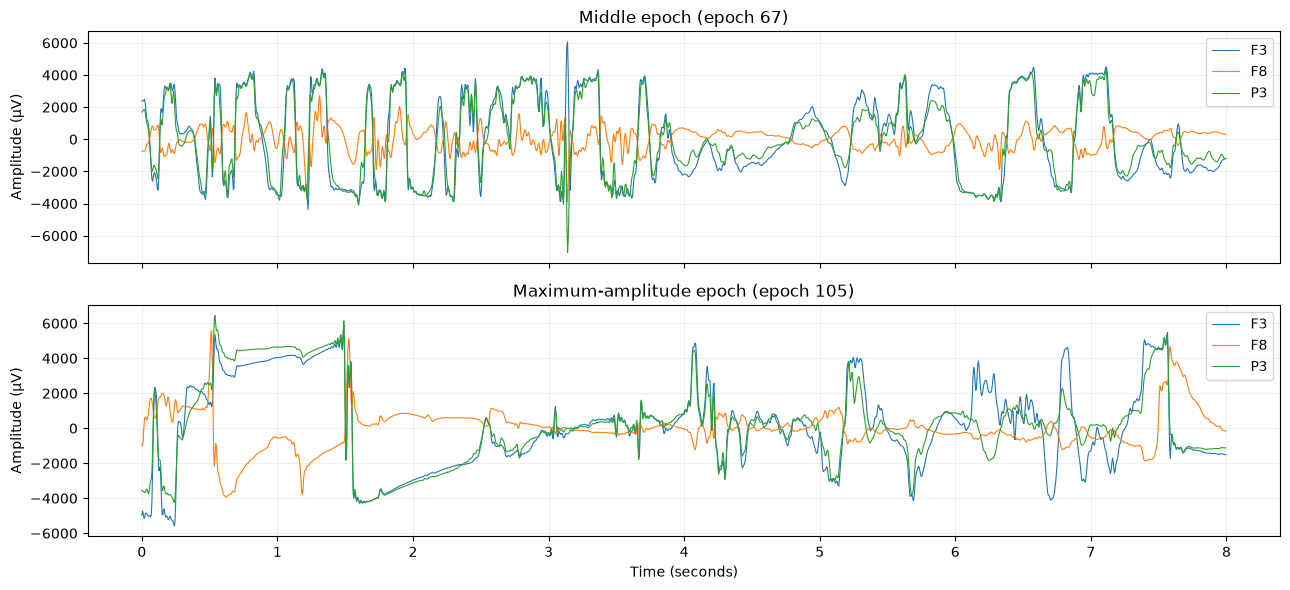


Patient: aaaaanvd
Label: normal
Recording: TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_t002.edf
Epochs: 148
Median epoch RMS (µV): 903.5061948406235
Maximum epoch RMS (µV): 1831.8712747394939
Maximum absolute amplitude (µV): 11435.561
Epochs with peak > 500 µV: 119
Epochs with peak > 1000 µV: 119


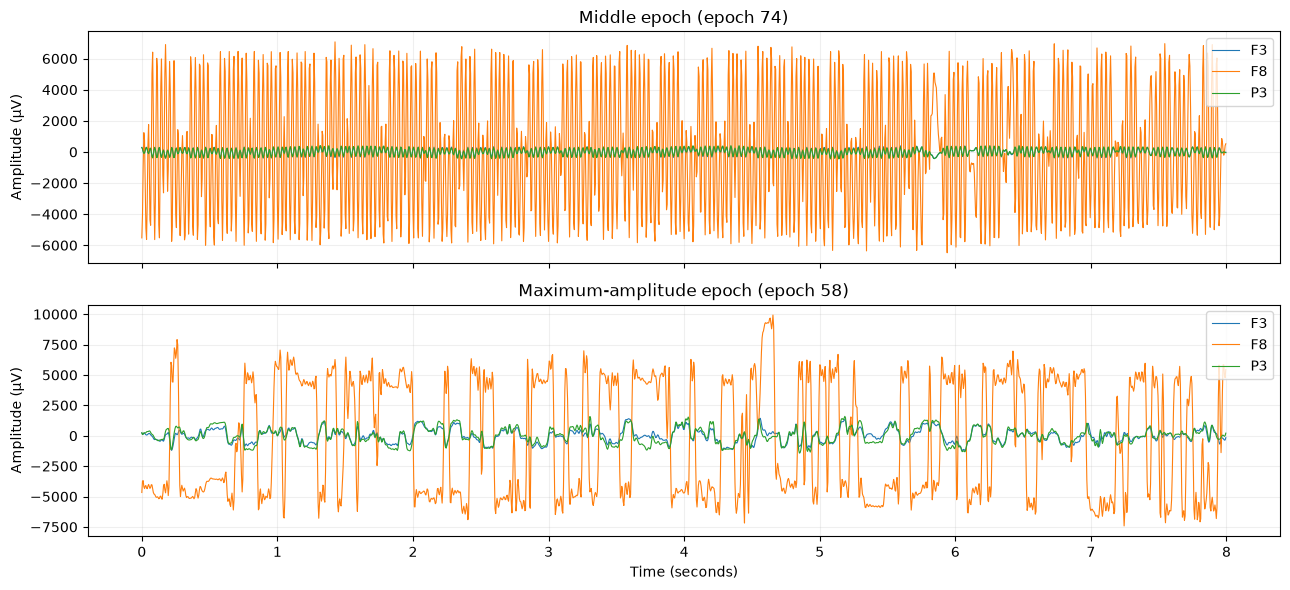


Extreme-recording signal audit: COMPLETED


In [33]:
suspect_patients = ["aaaaapaw", "aaaaanvd"]

for patient_id in suspect_patients:

    patient_records = train_df[
        train_df["patient_id"] == patient_id
    ]

    # Select the recording with the largest F3 RMS
    record = patient_records.loc[
        patient_records[
            "car__F3__rms__median"
        ].idxmax()
    ]

    metadata_row = metadata_df.loc[
        metadata_df["filepath"] == record["filepath"]
    ].iloc[0]

    npz_path = resolve_npz_path(
        metadata_row["output_file"]
    )

    with np.load(npz_path, allow_pickle=False) as data:
        epochs = data["original_reference"].copy()

    epochs_car = apply_car(epochs)

    # Amplitude metrics per epoch
    epoch_rms = np.sqrt(
        np.mean(
            epochs_car.astype(np.float64) ** 2,
            axis=(1, 2),
        )
    )

    epoch_peak = np.max(
        np.abs(epochs_car),
        axis=(1, 2),
    )

    print(f"\n{'=' * 60}")
    print("Patient:", patient_id)
    print("Label:", record["label"])
    print("Recording:", record["filepath"])
    print("Epochs:", len(epochs))

    print("Median epoch RMS (µV):", np.median(epoch_rms))
    print("Maximum epoch RMS (µV):", np.max(epoch_rms))
    print("Maximum absolute amplitude (µV):", np.max(epoch_peak))

    print("Epochs with peak > 500 µV:",
          int(np.sum(epoch_peak > 500)))

    print("Epochs with peak > 1000 µV:",
          int(np.sum(epoch_peak > 1000)))

    # Plot a representative epoch and the worst-amplitude epoch
    representative_idx = len(epochs) // 2
    extreme_idx = int(np.argmax(epoch_peak))

    fig, axes = plt.subplots(
        2, 1, figsize=(13, 6), sharex=True
    )

    t = np.arange(1600) / SFREQ

    for ax, idx, title in [
        (axes[0], representative_idx, "Middle epoch"),
        (axes[1], extreme_idx, "Maximum-amplitude epoch"),
    ]:
        for channel in ["F3", "F8", "P3"]:
            ch_idx = CHANNELS.index(channel)
            ax.plot(
                t,
                epochs_car[idx, ch_idx],
                label=channel,
                linewidth=0.8,
            )

        ax.set_title(f"{title} (epoch {idx})")
        ax.set_ylabel("Amplitude (µV)")
        ax.legend(loc="upper right")
        ax.grid(alpha=0.2)

    axes[-1].set_xlabel("Time (seconds)")
    plt.tight_layout()
    plt.show()

print("\nExtreme-recording signal audit: COMPLETED")

# Inspect preprocessing QC files

In [34]:
QC_DIR = PROJECT_ROOT / "tuab_preprocessing/full_tuab/qc"

assert QC_DIR.exists(), f"QC directory not found: {QC_DIR}"

qc_files = sorted(QC_DIR.rglob("*.csv"))

print("Total QC CSV files:", len(qc_files))

for path in qc_files[:15]:
    print(path.relative_to(QC_DIR))

print("\n" + "=" * 65)
print("QC file schema inspection")
print("=" * 65)

# Inspect a few representative files without loading all QC data
for path in qc_files[:5]:

    sample = pd.read_csv(path, nrows=5)

    print(f"\nFile: {path.name}")
    print("Columns:", sample.columns.tolist())
    print("Sample rows:")

    display(sample)

print("\nQC schema inspection: COMPLETED")

Total QC CSV files: 5986
001a1a63435de31f_channels.csv
001a1a63435de31f_qc.csv
001df6e81650d78e_channels.csv
001df6e81650d78e_qc.csv
0042ff0b27f34615_channels.csv
0042ff0b27f34615_qc.csv
0048754bb1adbf35_channels.csv
0048754bb1adbf35_qc.csv
004c2bc346b0d0ef_channels.csv
004c2bc346b0d0ef_qc.csv
005001633d365be7_channels.csv
005001633d365be7_qc.csv
00510b3d31b4946f_channels.csv
00510b3d31b4946f_qc.csv
007c1c93262f588a_channels.csv

QC file schema inspection

File: 001a1a63435de31f_channels.csv
Columns: ['epoch_index', 'channel', 'raw_ptp_uv', 'raw_max_abs_uv', 'raw_min_1s_ptp_uv', 'high_ptp_flag', 'high_abs_flag', 'flatline_flag']
Sample rows:


,epoch_index,channel,raw_ptp_uv,raw_max_abs_uv,raw_min_1s_ptp_uv,high_ptp_flag,high_abs_flag,flatline_flag
0,0,Fp1,5514.216877,4999.847000,11.291495,True,True,False
1,0,Fp2,8272.546017,4891.967446,11.444083,True,True,False
2,0,F3,755.919819,557.399628,11.749258,True,False,False
3,0,F4,5512.538411,4941.558471,11.749258,True,True,False
4,0,F7,6317.591492,4999.847000,11.291495,True,True,False



File: 001a1a63435de31f_qc.csv
Columns: ['epoch_index', 'suspect_channels', 'high_abs_channels', 'flatline_channels', 'max_raw_ptp_uv', 'channel_suspect', 'filter_boundary_flag', 'qc_status', 'use_for_training', 'recording_id', 'patient_id', 'label', 'split']
Sample rows:


,epoch_index,suspect_channels,high_abs_channels,flatline_channels,max_raw_ptp_uv,channel_suspect,filter_boundary_flag,qc_status,use_for_training,recording_id,patient_id,label,split
0,0,19,17,0,8272.546017,True,False,SUSPECT,True,aaaaalzg_s009_t000,aaaaalzg,normal,train
1,1,0,0,0,106.658852,False,False,NO_SCREENING_FLAGS,True,aaaaalzg_s009_t000,aaaaalzg,normal,train
2,2,19,17,0,6141.810380,True,False,SUSPECT,True,aaaaalzg_s009_t000,aaaaalzg,normal,train
3,3,0,0,0,151.367069,False,False,NO_SCREENING_FLAGS,True,aaaaalzg_s009_t000,aaaaalzg,normal,train
4,4,0,0,0,133.361712,False,False,NO_SCREENING_FLAGS,True,aaaaalzg_s009_t000,aaaaalzg,normal,train



File: 001df6e81650d78e_channels.csv
Columns: ['epoch_index', 'channel', 'raw_ptp_uv', 'raw_max_abs_uv', 'raw_min_1s_ptp_uv', 'high_ptp_flag', 'high_abs_flag', 'flatline_flag']
Sample rows:


...


File: 001df6e81650d78e_qc.csv
Columns: ['epoch_index', 'suspect_channels', 'high_abs_channels', 'flatline_channels', 'max_raw_ptp_uv', 'channel_suspect', 'filter_boundary_flag', 'qc_status', 'use_for_training', 'recording_id', 'patient_id', 'label', 'split']
Sample rows:


,epoch_index,suspect_channels,high_abs_channels,flatline_channels,max_raw_ptp_uv,channel_suspect,filter_boundary_flag,qc_status,use_for_training,recording_id,patient_id,label,split
0,0,0,0,0,196.075286,False,False,NO_SCREENING_FLAGS,True,aaaaalvf_s001_t001,aaaaalvf,abnormal,train
1,1,0,0,0,234.527404,False,False,NO_SCREENING_FLAGS,True,aaaaalvf_s001_t001,aaaaalvf,abnormal,train
2,2,0,0,0,151.519657,False,False,NO_SCREENING_FLAGS,True,aaaaalvf_s001_t001,aaaaalvf,abnormal,train
3,3,1,0,0,504.912935,True,False,SUSPECT,True,aaaaalvf_s001_t001,aaaaalvf,abnormal,train
4,4,0,0,0,154.876588,False,False,NO_SCREENING_FLAGS,True,aaaaalvf_s001_t001,aaaaalvf,abnormal,train



File: 0042ff0b27f34615_channels.csv
Columns: ['epoch_index', 'channel', 'raw_ptp_uv', 'raw_max_abs_uv', 'raw_min_1s_ptp_uv', 'high_ptp_flag', 'high_abs_flag', 'flatline_flag']
Sample rows:


,epoch_index,channel,raw_ptp_uv,raw_max_abs_uv,raw_min_1s_ptp_uv,high_ptp_flag,high_abs_flag,flatline_flag
0,0,Fp1,5502.009855,4999.084061,11.901846,True,True,False
1,0,Fp2,2755.124797,1627.657256,11.749258,True,True,False
2,0,F3,5356.135946,3170.472211,12.054434,True,True,False
3,0,F4,1831.511018,1122.126970,11.138907,True,True,False
4,0,F7,6857.294439,4999.847000,10.375968,True,True,False



QC schema inspection: COMPLETED


# Validate QC-to-NPZ alignment

In [35]:
# Select the six pilot recordings
validation_records = pilot_df.copy()

# Add the two extreme recordings
extreme_records = metadata_df[
    metadata_df["patient_id"].isin(
        ["aaaaapaw", "aaaaanvd"]
    )
]

validation_records = pd.concat(
    [validation_records, extreme_records],
    ignore_index=True,
).drop_duplicates(subset="filepath")

results = []

for _, record in validation_records.iterrows():

    npz_path = resolve_npz_path(
        record["output_file"]
    )

    # QC filename uses the same hash as the NPZ
    qc_path = QC_DIR / f"{npz_path.stem}_qc.csv"

    assert qc_path.exists(), (
        f"Missing QC file: {qc_path}"
    )

    qc = pd.read_csv(qc_path)

    with np.load(npz_path, allow_pickle=False) as data:
        n_epochs = data["original_reference"].shape[0]

    # Validate exact epoch mapping
    assert len(qc) == n_epochs
    assert qc["epoch_index"].is_unique

    np.testing.assert_array_equal(
        qc["epoch_index"].to_numpy(),
        np.arange(n_epochs),
    )

    # Verify recording metadata
    assert qc["patient_id"].eq(
        record["patient_id"]
    ).all()

    assert qc["label"].eq(
        record["label"]
    ).all()

    assert qc["split"].eq(
        record["split"]
    ).all()

    accepted = qc["qc_status"].eq(
        "NO_SCREENING_FLAGS"
    )

    results.append({
        "patient_id": record["patient_id"],
        "label": record["label"],
        "n_epochs": n_epochs,
        "accepted_epochs": int(accepted.sum()),
        "suspect_epochs": int((~accepted).sum()),
        "accepted_pct": round(
            100 * accepted.mean(), 2
        ),
    })

alignment_df = pd.DataFrame(results)

display(alignment_df)

print("Recordings validated:", len(alignment_df))
print(
    "Recordings with zero accepted epochs:",
    int((alignment_df["accepted_epochs"] == 0).sum())
)

print("\nQC-to-NPZ alignment: PASSED")

,patient_id,label,n_epochs,accepted_epochs,suspect_epochs,accepted_pct
0,aaaaapre,abnormal,155,137,18,88.39
1,aaaaambf,abnormal,275,269,6,97.82
2,aaaaaneo,abnormal,157,140,17,89.17
3,aaaaalyk,normal,245,234,11,95.51
4,aaaaaifx,normal,158,133,25,84.18
5,aaaaalhs,normal,158,156,2,98.73
6,aaaaapaw,abnormal,170,165,5,97.06
7,aaaaapaw,abnormal,135,0,135,0.00
8,aaaaanvd,normal,174,162,12,93.10
9,aaaaanvd,normal,178,157,21,88.20


Recordings validated: 11
Recordings with zero accepted epochs: 1

QC-to-NPZ alignment: PASSED


# Audit QC coverage across all 2,993 recordings

In [36]:
from tqdm.auto import tqdm

qc_coverage_results = []

for _, record in tqdm(
    metadata_df.iterrows(),
    total=len(metadata_df),
    desc="Auditing QC coverage",
):
    npz_path = resolve_npz_path(record["output_file"])
    qc_path = QC_DIR / f"{npz_path.stem}_qc.csv"

    assert qc_path.is_file(), f"Missing QC file: {qc_path}"

    qc = pd.read_csv(qc_path)

    # Validate recording identity
    assert qc["patient_id"].eq(record["patient_id"]).all()
    assert qc["label"].eq(record["label"]).all()
    assert qc["split"].eq(record["split"]).all()

    # Validate epoch indices against the processing manifest
    n_epochs = len(qc)

    assert qc["epoch_index"].is_unique
    np.testing.assert_array_equal(
        qc["epoch_index"].to_numpy(),
        np.arange(n_epochs),
    )

    accepted = qc["qc_status"].eq("NO_SCREENING_FLAGS")

    qc_coverage_results.append({
        "filepath": record["filepath"],
        "patient_id": record["patient_id"],
        "label": record["label"],
        "split": record["split"],
        "total_epochs": n_epochs,
        "accepted_epochs": int(accepted.sum()),
        "suspect_epochs": int((~accepted).sum()),
        "accepted_fraction": float(accepted.mean()),
    })

qc_coverage_df = pd.DataFrame(qc_coverage_results)

assert len(qc_coverage_df) == 2993
assert qc_coverage_df["filepath"].is_unique

print("Total recordings:", len(qc_coverage_df))

print(
    "Recordings with zero accepted epochs:",
    int((qc_coverage_df["accepted_epochs"] == 0).sum()),
)

print(
    "Recordings with at least one accepted epoch:",
    int((qc_coverage_df["accepted_epochs"] > 0).sum()),
)

print("\nAcceptance-rate distribution:")
print(
    qc_coverage_df["accepted_fraction"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print("\nZero-accepted recordings by split and label:")
print(
    qc_coverage_df[
        qc_coverage_df["accepted_epochs"] == 0
    ].groupby(["split", "label"]).size()
)

print("\nLowest acceptance rates:")
display(
    qc_coverage_df.nsmallest(
        15, "accepted_fraction"
    )
)

print("\nQC coverage audit: PASSED")

Auditing QC coverage:   0%|          | 0/2993 [00:00<?, ?it/s]

Total recordings: 2993
Recordings with zero accepted epochs: 14
Recordings with at least one accepted epoch: 2979

Acceptance-rate distribution:
count    2993.000000
mean        0.900259
std         0.157514
min         0.000000
1%          0.120682
5%          0.590172
25%         0.895833
50%         0.953642
75%         0.982036
95%         1.000000
99%         1.000000
max         1.000000
Name: accepted_fraction, dtype: float64

Zero-accepted recordings by split and label:
split  label   
train  abnormal    8
val    abnormal    4
       normal      2
dtype: int64

Lowest acceptance rates:


,filepath,patient_id,label,split,total_epochs,accepted_epochs,suspect_epochs,accepted_fraction
245,TUAB/edf/train/abnormal/01_tcp_ar/aaaaajnr_s00...,aaaaajnr,abnormal,train,150,0,150,0.00000
636,TUAB/edf/train/abnormal/01_tcp_ar/aaaaampk_s00...,aaaaampk,abnormal,train,342,0,342,0.00000
718,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanbp_s00...,aaaaanbp,abnormal,train,179,0,179,0.00000
722,TUAB/edf/train/abnormal/01_tcp_ar/aaaaancb_s00...,aaaaancb,abnormal,train,133,0,133,0.00000
729,TUAB/edf/train/abnormal/01_tcp_ar/aaaaandx_s00...,aaaaandx,abnormal,train,123,0,123,0.00000
751,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanky_s00...,aaaaanky,abnormal,train,185,0,185,0.00000
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,train,135,0,135,0.00000
1018,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapks_s00...,aaaaapks,abnormal,train,413,0,413,0.00000
2372,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanhm_s00...,aaaaanhm,abnormal,val,381,0,381,0.00000
2375,TUAB/edf/train/abnormal/01_tcp_ar/aaaaanjc_s00...,aaaaanjc,abnormal,val,129,0,129,0.00000



QC coverage audit: PASSED


# Visualize QC coverage

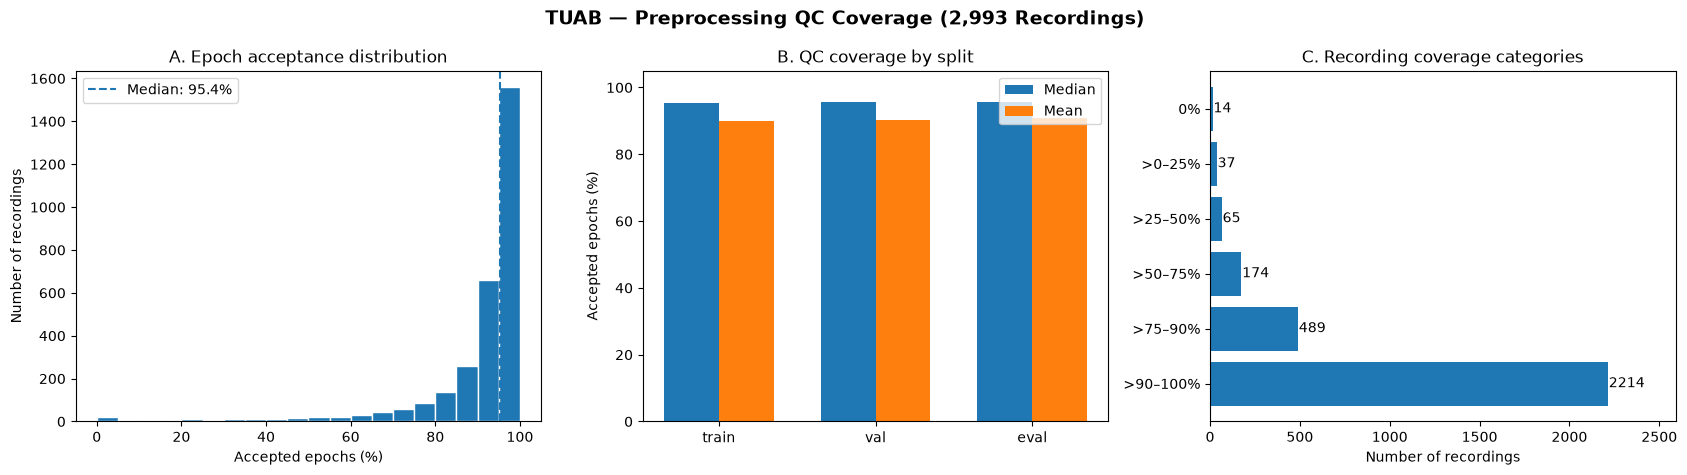

Figure saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/figures/Feature-Extraction/tuab_qc_coverage.png


In [37]:
qc_plot = qc_coverage_df.copy()
qc_plot["accepted_pct"] = qc_plot["accepted_fraction"] * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# A. Distribution of acceptance rates
axes[0].hist(
    qc_plot["accepted_pct"],
    bins=np.arange(0, 105, 5),
    edgecolor="white",
)
axes[0].axvline(
    qc_plot["accepted_pct"].median(),
    linestyle="--",
    label=f"Median: {qc_plot['accepted_pct'].median():.1f}%",
)
axes[0].set(
    title="A. Epoch acceptance distribution",
    xlabel="Accepted epochs (%)",
    ylabel="Number of recordings",
)
axes[0].legend()

# B. QC coverage by split
split_summary = (
    qc_plot.groupby("split")["accepted_pct"]
    .agg(["median", "mean"])
    .reindex(["train", "val", "eval"])
)

x = np.arange(len(split_summary))
width = 0.35

axes[1].bar(
    x - width / 2,
    split_summary["median"],
    width,
    label="Median",
)
axes[1].bar(
    x + width / 2,
    split_summary["mean"],
    width,
    label="Mean",
)
axes[1].set_xticks(x, split_summary.index)
axes[1].set_ylim(0, 105)
axes[1].set(
    title="B. QC coverage by split",
    ylabel="Accepted epochs (%)",
)
axes[1].legend()

# C. Recording coverage categories
bins = [-0.001, 0, 0.25, 0.50, 0.75, 0.90, 1.0]
labels = [
    "0%",
    ">0–25%",
    ">25–50%",
    ">50–75%",
    ">75–90%",
    ">90–100%",
]

coverage_categories = pd.cut(
    qc_plot["accepted_fraction"],
    bins=bins,
    labels=labels,
    include_lowest=True,
)

counts = coverage_categories.value_counts().reindex(labels)

axes[2].barh(labels, counts)
axes[2].invert_yaxis()
axes[2].set(
    title="C. Recording coverage categories",
    xlabel="Number of recordings",
)
for i, count in enumerate(counts):
    axes[2].text(count + 5, i, str(count), va="center")
axes[2].set_xlim(0, counts.max() * 1.17)

fig.suptitle(
    "TUAB — Preprocessing QC Coverage (2,993 Recordings)",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()

figure_dir = PROJECT_ROOT / "reports/figures/Feature-Extraction"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "tuab_qc_coverage.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

In [38]:
import inspect

print(inspect.getsource(extract_recording_features))

def extract_recording_features(npz_path):
    with np.load(npz_path, allow_pickle=False) as data:
        epochs = data["original_reference"]
        sfreq = float(data["sfreq"])
        channels = list(data["channels"])

    assert sfreq == SFREQ
    assert channels == CHANNELS
    assert epochs.ndim == 3
    assert epochs.shape[1:] == (19, 1600)
    assert np.isfinite(epochs).all()

    # Apply dynamic common average reference
    epochs_car = apply_car(epochs)

    # Spectral extraction
    recording_freqs, recording_psd = compute_welch_psd(
        epochs_car
    )

    band_features, _ = extract_band_powers(
        recording_freqs,
        recording_psd,
    )

    spectral_descriptors = extract_spectral_descriptors(
        recording_freqs,
        recording_psd,
        band_features,
    )

    # Temporal extraction
    temporal_features = extract_temporal_features(
        epochs_car
    )

    # Channel-level aggregation
    channel_features = aggregate_recording_features(
 

# QC-aware feature extraction (pilot)

In [39]:
def extract_recording_features_qc(npz_path, qc_path):
    with np.load(npz_path, allow_pickle=False) as data:
        epochs = data["original_reference"]
        sfreq = float(data["sfreq"])
        channels = list(data["channels"])

    assert sfreq == SFREQ
    assert channels == CHANNELS
    assert epochs.ndim == 3
    assert epochs.shape[1:] == (19, 1600)
    assert np.isfinite(epochs).all()

    qc = pd.read_csv(qc_path)

    assert len(qc) == len(epochs)
    assert qc["epoch_index"].is_unique

    np.testing.assert_array_equal(
        qc["epoch_index"].to_numpy(),
        np.arange(len(epochs)),
    )

    assert qc["qc_status"].notna().all()

    # Use the original preprocessing QC decision
    accepted_mask = (
        qc["qc_status"] == "NO_SCREENING_FLAGS"
    ).to_numpy()

    n_accepted = int(accepted_mask.sum())

    # Do not fabricate features when no epochs remain
    if n_accepted == 0:
        return None, {
            "total_epochs": len(epochs),
            "accepted_epochs": 0,
            "accepted_fraction": 0.0,
        }

    epochs = epochs[accepted_mask]

    # Identical feature extraction pipeline
    epochs_car = apply_car(epochs)

    freqs, psd = compute_welch_psd(epochs_car)

    band_features, _ = extract_band_powers(
        freqs, psd
    )

    spectral_descriptors = extract_spectral_descriptors(
        freqs, psd, band_features
    )

    temporal_features = extract_temporal_features(
        epochs_car
    )

    channel_features = aggregate_recording_features(
        band_features,
        spectral_descriptors,
        temporal_features,
    )

    regional_features = aggregate_regional_features(
        band_features,
        spectral_descriptors,
        temporal_features,
    )

    features = {
        **channel_features,
        **regional_features,
    }

    return features, {
        "total_epochs": len(accepted_mask),
        "accepted_epochs": n_accepted,
        "accepted_fraction": float(accepted_mask.mean()),
    }


# Pilot: six previously selected recordings
pilot_results = []

for _, record in pilot_df.iterrows():
    npz_path = resolve_npz_path(record["output_file"])
    qc_path = QC_DIR / f"{npz_path.stem}_qc.csv"

    features, coverage = extract_recording_features_qc(
        npz_path, qc_path
    )

    assert features is not None
    assert set(features) == set(FEATURE_COLUMNS)
    assert len(features) == 1152
    assert np.isfinite(
        np.array(list(features.values()), dtype=float)
    ).all()

    pilot_results.append({
        "patient_id": record["patient_id"],
        "label": record["label"],
        **coverage,
        "feature_count": len(features),
    })

display(pd.DataFrame(pilot_results))


# Test zero-accepted-epoch handling
zero_record = qc_coverage_df.loc[
    qc_coverage_df["accepted_epochs"] == 0
].iloc[0]

zero_metadata = metadata_df.loc[
    metadata_df["filepath"] == zero_record["filepath"]
].iloc[0]

zero_npz = resolve_npz_path(zero_metadata["output_file"])
zero_qc = QC_DIR / f"{zero_npz.stem}_qc.csv"

zero_features, zero_coverage = extract_recording_features_qc(
    zero_npz, zero_qc
)

assert zero_features is None
assert zero_coverage["accepted_epochs"] == 0

print("\nZero-epoch handling: PASSED")
print("QC-aware feature extraction pilot: PASSED")

,patient_id,label,total_epochs,accepted_epochs,accepted_fraction,feature_count
0,aaaaapre,abnormal,155,137,0.883871,1152
1,aaaaambf,abnormal,275,269,0.978182,1152
2,aaaaaneo,abnormal,157,140,0.891720,1152
3,aaaaalyk,normal,245,234,0.955102,1152
4,aaaaaifx,normal,158,133,0.841772,1152
5,aaaaalhs,normal,158,156,0.987342,1152



Zero-epoch handling: PASSED
QC-aware feature extraction pilot: PASSED


# Full QC-aware extraction with checkpoints

In [40]:
import time
from pathlib import Path
from tqdm.auto import tqdm

QC_FE_DIR = PROJECT_ROOT / "tuab_feature_extraction"
QC_FEATURE_PATH = QC_FE_DIR / "features/tuab_recording_features_qc.parquet"
QC_CHECKPOINT_PATH = QC_FE_DIR / "checkpoints/qc_extraction_progress.csv"
QC_COVERAGE_PATH = QC_FE_DIR / "metadata/qc_feature_coverage.csv"
QC_ERROR_PATH = QC_FE_DIR / "logs/qc_extraction_errors.csv"

for path in [
    QC_FEATURE_PATH,
    QC_CHECKPOINT_PATH,
    QC_COVERAGE_PATH,
    QC_ERROR_PATH,
]:
    path.parent.mkdir(parents=True, exist_ok=True)

META_COLUMNS = ["filepath", "patient_id", "label", "split"]
QC_META_COLUMNS = [
    "total_epochs", "accepted_epochs", "accepted_fraction"
]

# Resume from checkpoint if available
if QC_CHECKPOINT_PATH.exists():
    completed_df = pd.read_csv(QC_CHECKPOINT_PATH)
    print("Resuming checkpoint:", len(completed_df), "rows")
else:
    completed_df = pd.DataFrame()

completed_paths = (
    set(completed_df["filepath"])
    if "filepath" in completed_df.columns
    else set()
)

pending = metadata_df.loc[
    ~metadata_df["filepath"].isin(completed_paths)
].copy()

print("Total recordings:", len(metadata_df))
print("Already completed:", len(completed_paths))
print("Remaining:", len(pending))

buffer = []
errors = []
start = time.time()

def save_qc_checkpoint(rows):
    if not rows:
        return

    batch = pd.DataFrame(rows)

    if QC_CHECKPOINT_PATH.exists():
        batch.to_csv(
            QC_CHECKPOINT_PATH,
            mode="a",
            header=False,
            index=False,
        )
    else:
        batch.to_csv(
            QC_CHECKPOINT_PATH,
            index=False,
        )

for _, record in tqdm(
    pending.iterrows(),
    total=len(pending),
    desc="QC-aware feature extraction",
):
    filepath = record["filepath"]

    try:
        npz_path = resolve_npz_path(record["output_file"])
        qc_path = QC_DIR / f"{npz_path.stem}_qc.csv"

        features, coverage = extract_recording_features_qc(
            npz_path, qc_path
        )

        row = {
            col: record[col]
            for col in META_COLUMNS
        }
        row.update(coverage)

        if features is None:
            row.update({
                col: np.nan for col in FEATURE_COLUMNS
            })
        else:
            assert set(features) == set(FEATURE_COLUMNS)
            row.update(features)

        buffer.append(row)

        if len(buffer) >= 25:
            save_qc_checkpoint(buffer)
            buffer.clear()

    except Exception as exc:
        errors.append({
            "filepath": filepath,
            "error": repr(exc),
        })

# Save final partial batch
save_qc_checkpoint(buffer)

if errors:
    pd.DataFrame(errors).to_csv(QC_ERROR_PATH, index=False)

print("\nExtraction duration (minutes):",
      round((time.time() - start) / 60, 2))
print("Errors:", len(errors))

# Read and validate checkpoint
qc_features_df = pd.read_csv(QC_CHECKPOINT_PATH)

assert qc_features_df["filepath"].is_unique
assert set(qc_features_df["filepath"]) == set(metadata_df["filepath"])
assert len(qc_features_df) == 2993

# Preserve original feature schema
qc_features_df = qc_features_df[
    META_COLUMNS + QC_META_COLUMNS + FEATURE_COLUMNS
]

eligible = qc_features_df["accepted_epochs"] > 0
feature_values = qc_features_df.loc[eligible, FEATURE_COLUMNS]

assert feature_values.notna().all().all()
assert np.isfinite(feature_values.to_numpy(dtype=float)).all()

assert qc_features_df.loc[
    ~eligible, FEATURE_COLUMNS
].isna().all().all()

# Save full QC dataset, including missing-feature records
qc_features_df.to_parquet(
    QC_FEATURE_PATH,
    index=False,
)

# Save coverage separately for audit and reporting
qc_features_df[
    META_COLUMNS + QC_META_COLUMNS
].to_csv(QC_COVERAGE_PATH, index=False)

print("\nQC feature dataset:", qc_features_df.shape)
print("Eligible recordings:", int(eligible.sum()))
print("Zero-accepted recordings:", int((~eligible).sum()))
print("Feature columns:", len(FEATURE_COLUMNS))
print("Saved:", QC_FEATURE_PATH)
print("Full QC extraction: PASSED")

Total recordings: 2993
Already completed: 0
Remaining: 2993


QC-aware feature extraction:   0%|          | 0/2993 [00:00<?, ?it/s]


Extraction duration (minutes): 33.05
Errors: 0

QC feature dataset: (2993, 1159)
Eligible recordings: 2979
Zero-accepted recordings: 14
Feature columns: 1152
Saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/features/tuab_recording_features_qc.parquet
Full QC extraction: PASSED


# Compare FE-All vs FE-QC

In [41]:
fe_all = pd.read_parquet(
    PROJECT_ROOT
    / "tuab_feature_extraction/features/tuab_recording_features.parquet"
)

fe_qc = pd.read_parquet(
    PROJECT_ROOT
    / "tuab_feature_extraction/features/tuab_recording_features_qc.parquet"
)

assert len(fe_all) == len(fe_qc) == 2993
assert fe_all["filepath"].is_unique
assert fe_qc["filepath"].is_unique

paired = fe_all.merge(
    fe_qc,
    on="filepath",
    suffixes=("_all", "_qc"),
    validate="one_to_one",
)

# Verify metadata consistency
for col in ["patient_id", "label", "split"]:
    assert (
        paired[f"{col}_all"] == paired[f"{col}_qc"]
    ).all()

eligible = paired["accepted_epochs"] > 0
paired_eligible = paired.loc[eligible]

print("Paired eligible recordings:", len(paired_eligible))

# Inspect previously identified extreme features
selected_features = [
    "car__P3__theta_absolute_power__iqr",
    "car__F3__rms__median",
    "car__F8__low_gamma_absolute_power__median",
]

comparison = []

for feature in selected_features:
    all_values = paired_eligible[f"{feature}_all"]
    qc_values = paired_eligible[f"{feature}_qc"]

    comparison.append({
        "feature": feature,
        "FE_All_max": all_values.max(),
        "FE_QC_max": qc_values.max(),
        "FE_All_p99": all_values.quantile(0.99),
        "FE_QC_p99": qc_values.quantile(0.99),
        "FE_All_median": all_values.median(),
        "FE_QC_median": qc_values.median(),
    })

display(pd.DataFrame(comparison))

# Inspect extreme patients by individual recording
extreme_patients = paired[
    paired["patient_id_all"].isin(
        ["aaaaapaw", "aaaaanvd"]
    )
]

display(
    extreme_patients[
        [
            "filepath",
            "patient_id_all",
            "label_all",
            "accepted_epochs",
            "accepted_fraction",
            "car__F3__rms__median_all",
            "car__F3__rms__median_qc",
            "car__F8__low_gamma_absolute_power__median_all",
            "car__F8__low_gamma_absolute_power__median_qc",
        ]
    ]
)

print("\nFE-All vs FE-QC comparison: COMPLETED")

Paired eligible recordings: 2979


,feature,FE_All_max,FE_QC_max,FE_All_p99,FE_QC_p99,FE_All_median,FE_QC_median
0,car__P3__theta_absolute_power__iqr,1.294043e+03,174.673694,57.023158,49.389334,2.450508,2.317391
1,car__F3__rms__median,2.135447e+02,49.092684,28.045597,25.124420,6.874933,6.625681
2,car__F8__low_gamma_absolute_power__median,9.857133e+06,502.721321,44.836549,30.259689,0.843780,0.799519


,filepath,patient_id_all,label_all,accepted_epochs,accepted_fraction,car__F3__rms__median_all,car__F3__rms__median_qc,car__F8__low_gamma_absolute_power__median_all,car__F8__low_gamma_absolute_power__median_qc
980,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,165,0.970588,9.565120,9.358087,1.947390e-01,0.194449
981,TUAB/edf/train/abnormal/01_tcp_ar/aaaaapaw_s00...,aaaaapaw,abnormal,0,0.000000,1916.557390,NaN,5.413960e+03,NaN
1825,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s001_...,aaaaanvd,normal,162,0.931034,5.186624,5.092729,6.134469e-01,0.588464
1826,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s002_...,aaaaanvd,normal,157,0.882022,5.009230,4.834441,6.513191e-01,0.606723
1827,TUAB/edf/train/normal/01_tcp_ar/aaaaanvd_s006_...,aaaaanvd,normal,28,0.189189,213.544650,10.396370,9.857133e+06,1.838336



FE-All vs FE-QC comparison: COMPLETED


# Visualize FE-All vs FE-QC

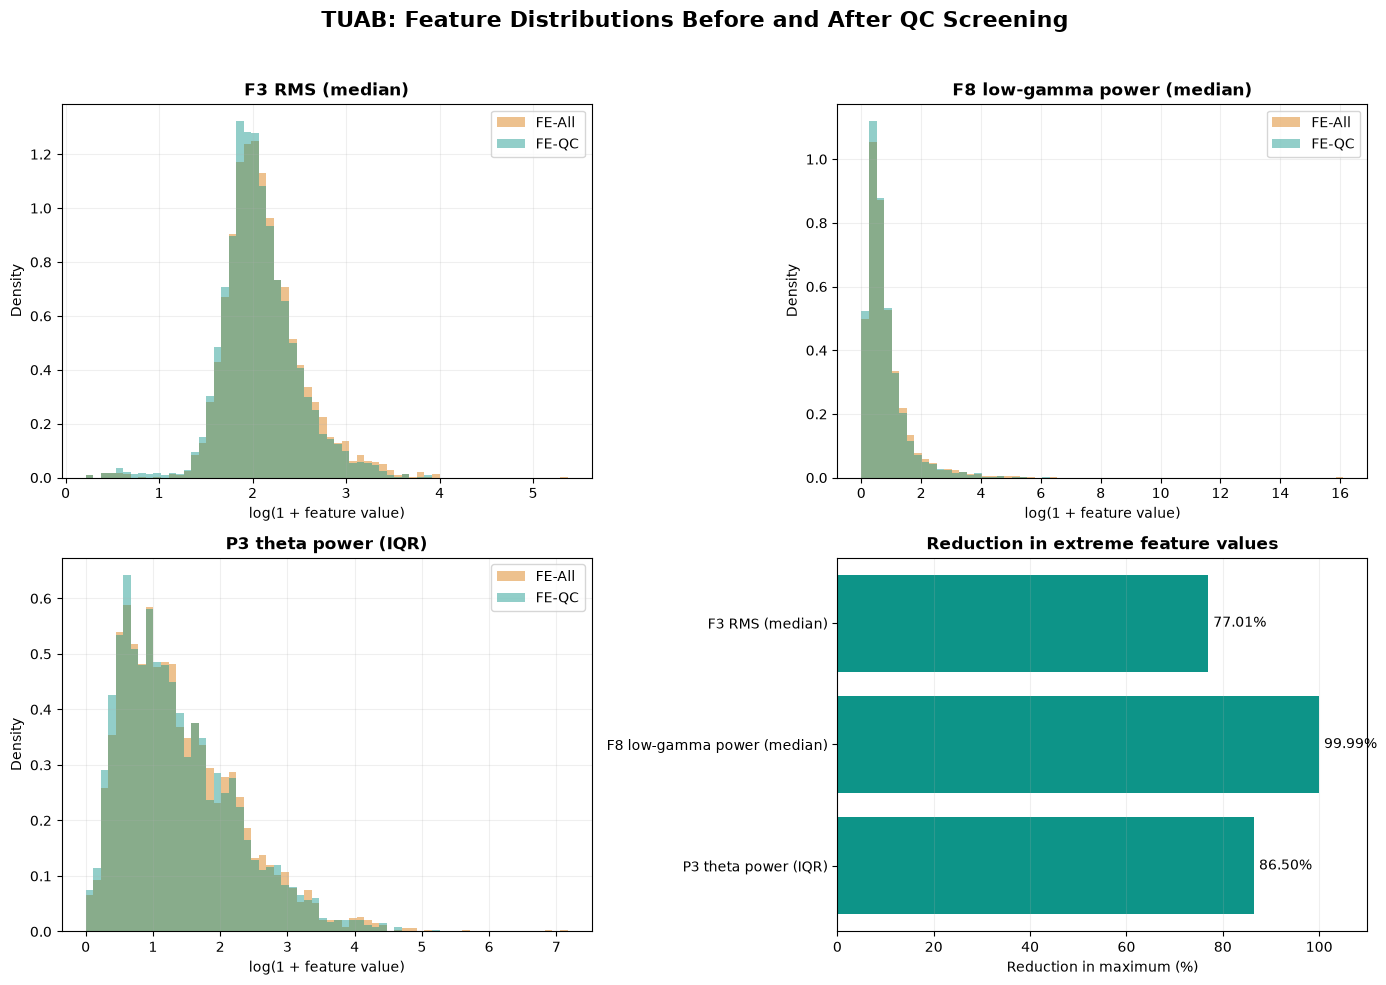

Paired recordings: 2979
Figure saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/figures/Feature-Extraction/tuab_fe_all_vs_qc.png


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use the paired dataframe from Cell 29
df = paired.loc[paired["accepted_epochs"] > 0].copy()

features = {
    "F3 RMS (median)": "car__F3__rms__median",
    "F8 low-gamma power (median)": "car__F8__low_gamma_absolute_power__median",
    "P3 theta power (IQR)": "car__P3__theta_absolute_power__iqr",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

colors = {
    "FE-All": "#D97706",
    "FE-QC": "#0D9488",
}

# Panels A–C: paired feature distributions
for ax, (title, feature) in zip(axes.flat[:3], features.items()):

    all_values = df[f"{feature}_all"].to_numpy(dtype=float)
    qc_values = df[f"{feature}_qc"].to_numpy(dtype=float)

    assert np.all(all_values >= 0)
    assert np.all(qc_values >= 0)

    all_log = np.log1p(all_values)
    qc_log = np.log1p(qc_values)

    bins = np.linspace(
        min(all_log.min(), qc_log.min()),
        max(all_log.max(), qc_log.max()),
        65,
    )

    ax.hist(
        all_log,
        bins=bins,
        density=True,
        alpha=0.45,
        color=colors["FE-All"],
        label="FE-All",
    )

    ax.hist(
        qc_log,
        bins=bins,
        density=True,
        alpha=0.45,
        color=colors["FE-QC"],
        label="FE-QC",
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("log(1 + feature value)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

# Panel D: change in extreme feature values
labels = list(features.keys())

reductions = []

for feature in features.values():
    all_max = df[f"{feature}_all"].max()
    qc_max = df[f"{feature}_qc"].max()

    reduction = 100 * (1 - qc_max / all_max)
    reductions.append(reduction)

ax = axes[1, 1]

bars = ax.barh(
    labels,
    reductions,
    color=colors["FE-QC"],
)

ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("Reduction in maximum (%)")
ax.set_title(
    "Reduction in extreme feature values",
    fontweight="bold",
)

for bar, value in zip(bars, reductions):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
    )

ax.grid(axis="x", alpha=0.2)

fig.suptitle(
    "TUAB: Feature Distributions Before and After QC Screening",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save figure
figure_dir = (
    PROJECT_ROOT
    / "reports/figures/Feature-Extraction"
)
figure_dir.mkdir(parents=True, exist_ok=True)

output_path = figure_dir / "tuab_fe_all_vs_qc.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Paired recordings:", len(df))
print("Figure saved:", output_path)

# Audit class-dependent QC selection

In [42]:
from scipy.integrate import trapezoid

def integrate_psd_band(freqs, psd, low, high):
    """
    Integrate PSD over [low, high], interpolating
    the PSD at exact band boundaries.

    PSD units: µV²/Hz
    Output units: µV²
    """
    freqs = np.asarray(freqs)

    assert low >= freqs[0]
    assert high <= freqs[-1]
    assert low < high

    inside = (freqs > low) & (freqs < high)

    band_freqs = np.concatenate([
        [low],
        freqs[inside],
        [high],
    ])

    # Interpolate PSD at both boundaries
    left_idx = np.searchsorted(freqs, low, side="right") - 1
    right_idx = np.searchsorted(freqs, high, side="right") - 1

    left_idx = min(max(left_idx, 0), len(freqs) - 2)
    right_idx = min(max(right_idx, 0), len(freqs) - 2)

    def interpolate_at(value, idx):
        f0, f1 = freqs[idx], freqs[idx + 1]
        weight = (value - f0) / (f1 - f0)
        return (
            psd[..., idx] * (1 - weight)
            + psd[..., idx + 1] * weight
        )

    left_power = interpolate_at(low, left_idx)
    right_power = interpolate_at(high, right_idx)

    band_psd = np.concatenate([
        left_power[..., None],
        psd[..., inside],
        right_power[..., None],
    ], axis=-1)

    return trapezoid(
        band_psd,
        x=band_freqs,
        axis=-1,
    )


def extract_band_powers(freqs, psd, bands=BANDS):
    features = {}

    total_power = integrate_psd_band(
        freqs, psd, 0.5, 40.0
    )

    for band_name, (low, high) in bands.items():
        band_power = integrate_psd_band(
            freqs, psd, low, high
        )

        features[f"{band_name}_absolute_power"] = band_power
        features[f"{band_name}_relative_power"] = (
            band_power / np.maximum(total_power, 1e-12)
        )

    return features, total_power


spectral_features, total_power = extract_band_powers(
    freqs, pilot_psd
)

# Validate conservation of integrated power
sum_band_power = sum(
    spectral_features[f"{band}_absolute_power"]
    for band in BANDS
)

relative_error = np.max(
    np.abs(sum_band_power - total_power)
    / np.maximum(total_power, 1e-12)
)

print("Extracted features:", len(spectral_features))
print("Maximum band-power conservation error:", relative_error)

assert relative_error < 1e-5
assert all(
    np.isfinite(values).all()
    for values in spectral_features.values()
)

print("\nCorrected band-power validation: PASSED")

Extracted features: 10
Maximum band-power conservation error: 0.0

Corrected band-power validation: PASSED


# Final class-dependent QC audit

In [44]:
qc = qc_coverage_df.copy()

summary = (
    qc.groupby(["split", "label"])
    .agg(
        recordings=("filepath", "size"),
        total_epochs=("total_epochs", "sum"),
        accepted_epochs=("accepted_epochs", "sum"),
        mean_acceptance=("accepted_fraction", "mean"),
        median_acceptance=("accepted_fraction", "median"),
        zero_accepted=("accepted_epochs", lambda x: (x == 0).sum()),
        low_coverage_25pct=("accepted_fraction", lambda x: (x < 0.25).sum()),
    )
    .reset_index()
)

summary["epoch_acceptance_pct"] = (
    100 * summary["accepted_epochs"] / summary["total_epochs"]
)

summary["mean_acceptance"] *= 100
summary["median_acceptance"] *= 100

display(summary.round(2))

# Compare abnormal vs normal acceptance rates
comparison = summary.pivot(
    index="split",
    columns="label",
    values="mean_acceptance"
)

comparison["abnormal_minus_normal_pp"] = (
    comparison["abnormal"] - comparison["normal"]
)

print("\nClass-dependent acceptance difference:")
display(comparison.round(2))

# Validate coverage accounting
assert len(qc) == 2993
assert (qc["total_epochs"] ==
        qc["accepted_epochs"] + qc["suspect_epochs"]).all()
assert (qc["accepted_epochs"] == 0).sum() == 14
assert qc["filepath"].is_unique

# Save audit results
audit_dir = PROJECT_ROOT / "tuab_feature_extraction/metadata"
audit_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    audit_dir / "qc_class_coverage_summary.csv",
    index=False
)

comparison.to_csv(
    audit_dir / "qc_class_acceptance_difference.csv"
)

print("\nQC class audit: PASSED")
print("Feature extraction audit: COMPLETED")

,split,label,recordings,total_epochs,accepted_epochs,mean_acceptance,median_acceptance,zero_accepted,low_coverage_25pct,epoch_acceptance_pct
0,eval,abnormal,126,21311,19243,90.15,95.88,0,1,90.30
1,eval,normal,150,24892,22784,91.44,95.51,0,3,91.53
2,train,abnormal,1076,190231,163226,87.18,94.86,8,33,85.80
3,train,normal,1097,183987,169961,92.52,95.45,0,3,92.38
4,val,abnormal,270,45912,40762,89.38,96.02,4,8,88.78
5,val,normal,274,45804,41601,90.99,95.33,2,3,90.82



Class-dependent acceptance difference:


label,abnormal,normal,abnormal_minus_normal_pp
split,,,
eval,90.15,91.44,-1.30
train,87.18,92.52,-5.34
val,89.38,90.99,-1.61



QC class audit: PASSED
Feature extraction audit: COMPLETED
